# Perbandingan 3 Algoritma Default *From Scratch* untuk Estimasi Harga Tanah Solo Raya 2020

Notebook ini menyajikan audit metodologis lengkap serta pemodelan harga tanah rata-rata per meter persegi (`harga_tanah_rata_rata_rp_m2`) pada **127 kecamatan di 7 kabupaten/kota Solo Raya tahun 2020** menggunakan dataset gabungan bersih (`data/processed/dataset_solo_raya_2020_bersih.csv`).

### Ruang Lingkup & Prinsip Utama
1. **Hanya 3 Algoritma Default *From Scratch***: **Geographically Weighted Regression (GWR)**, **K-Nearest Neighbors (KNN)**, dan **Decision Tree (CART)** diimplementasikan 100% dari awal hanya dengan komputasi numerik dasar (`numpy`, `pandas`, `math`) **tanpa** pustaka ML eksternal (`sklearn`, `mgwr`, `statsmodels`, `scipy`).
2. **Hyperparameter & Varian Default Saja (Zero Tuning)**: Tidak ada *grid search*, `Sel_BW`, maupun optimasi hyperparameter berbasis target; setiap algoritma dijalankan pada konfigurasi default standarnya.
3. **Kurasi Fitur Non-Kolinear Bebas Kebocoran (*Unsupervised VIF*)**: Redundansi komposisional tutupan lahan ESA WorldCover dan duplikasi jumlah–kepadatan diaudit secara *unsupervised* menggunakan **VIF** dan **Condition Number**, lalu dievaluasi pada himpunan fitur non-kolinear (`VIF4`, maks VIF = `2,05`) dengan perbandingan diagnostik terhadap 7 fitur mentah (`ALL7`).
4. **Validasi Spasial Tanpa Kebocoran Data**: Validasi silang **Leave-One-Kabupaten/Kota-Out (LOKO, 7 lipatan)** — pada setiap lipatan, parameter standardisasi Z-score (dan faktor *smearing* Duan pada uji diagnostik $\ln y$) dihitung **hanya dari bagian latih** sebelum diterapkan ke kabupaten/kota uji.
5. **Siap Presentasi & Terverifikasi**: Seluruh metrik komprehensif (`MAE`, `MdAE`, `RMSE`, `R²`, `WAPE`, `MAPE`, `Bias`, `RMSLE`, `Prediksi < 0`, `Moran's I Residu`) beserta 7 grafik resolusi tinggi (`220 dpi`) diekspor ke `figures/presentasi_3_model/`.

In [1]:
import math
import sys
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns

# Verifikasi kepatuhan R2: nol impor pustaka ML eksternal pada modul utama notebook
FORBIDDEN_ML_MODULES = ["sklearn", "mgwr", "statsmodels", "xgboost", "lightgbm", "catboost", "torch"]
for mod_name in FORBIDDEN_ML_MODULES:
    assert mod_name not in sys.modules, f"Pustaka ML terlarang terdeteksi: {mod_name}"
assert "scipy" not in globals(), "Modul scipy tidak diimpor oleh notebook ini."

# Resolusi path portabel: mendukung root lokal, folder notebooks/, maupun Google Colab (/content)
CWD = Path.cwd().resolve()
if (CWD / "data" / "processed" / "dataset_solo_raya_2020_bersih.csv").exists():
    ROOT = CWD
elif (CWD.parent / "data" / "processed" / "dataset_solo_raya_2020_bersih.csv").exists():
    ROOT = CWD.parent
else:
    ROOT = CWD

DATA_PROCESSED_DIR = ROOT / "data" / "processed"
DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/sqiftree/LandPredict/main/data/processed"

for fname in ("dataset_solo_raya_2020_bersih.csv", "audit_koordinat_127.csv"):
    target_file = DATA_PROCESSED_DIR / fname
    if not target_file.exists():
        url = f"{GITHUB_RAW_BASE}/{fname}"
        print(f"Mengunduh {fname} dari GitHub ke {target_file} ...")
        urllib.request.urlretrieve(url, target_file)

DATASET_PATH = DATA_PROCESSED_DIR / "dataset_solo_raya_2020_bersih.csv"
AUDIT_KOORD_PATH = DATA_PROCESSED_DIR / "audit_koordinat_127.csv"
FIG_DIR = ROOT / "figures" / "presentasi_3_model"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Pengaturan gaya visualisasi presentasi
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.02)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12.0
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10.2

def fmt_rupiah_axis(x, _pos):
    if abs(x) >= 1_000_000:
        return f"Rp {x / 1_000_000:.1f} jt"
    if abs(x) >= 1_000:
        return f"Rp {x / 1_000:.0f} rb"
    return f"Rp {x:.0f}"

print("Root proyek :", ROOT)
print("Folder figur:", FIG_DIR.relative_to(ROOT))
print("Kepatuhan R2: Lolos (0 pustaka ML eksternal diimpor)")


Root proyek : /mnt/data/UserFiles/Documents/KULIAH/SEM5/Machine Learning/tubes/LandPredict
Folder figur: figures/presentasi_3_model
Kepatuhan R2: Lolos (0 pustaka ML eksternal diimpor)


## 1. Konsolidasi Dataset & Verifikasi Koordinat Spasial

Dataset gabungan bersih (`data/processed/dataset_solo_raya_2020_bersih.csv`) dibangun oleh `scripts/build_clean_dataset.py` melalui *inner join* kunci unik `(kab_kota, kecamatan)` dari tiga sumber asli:
- `data/harga_tanah_2020.csv` (target harga tanah rata-rata kecamatan 2020, jumlah penduduk, jumlah fasilitas umum regional)
- `data/processed/variabel_pendukung_2020.csv` (luas poligon UTM 49S, kepadatan proksi, tutupan lahan ESA WorldCover 2020)
- `data/koordinat.csv` (koordinat interior terverifikasi **BIG KSP Satu Peta** melalui `ST_PointOnSurface`)

### Ringkasan Pembersihan Kolom (33 kolom mentah $\rightarrow$ 18 kolom bersih) & Audit Koordinat
- **15 kolom dihapus**: duplikat hasil *join*, metadata konstan (`tahun=2020`, `worldcover_valid_pct=100`), alias tutupan lahan identik, luas raster redundan, serta 3 kelas WorldCover bernilai nol konstan (`snow`, `mangrove`, `moss`).
- **18 kolom dipertahankan**: 5 identitas/koordinat/target, **7 prediktor inti** (`ALL7`), serta 6 kolom tambahan (`luas_arsip_km2` dan 5 kelas minor WorldCover) khusus untuk inspeksi korelasi EDA.
- **Audit 127 Koordinat (`audit_koordinat_127.csv`)**: Verifikasi silang terhadap BIG KSP Satu Peta, Kemendagri (`wilayah.id`), BPS/HDX COD-AB, GADM v4.1, dan OpenStreetMap Nominatim memastikan **`data/koordinat.csv` valid 127/127 (100%) di dalam poligon BIG**, sedangkan koordinat Colab lama (`GADM v4.1`) memiliki 2 titik jatuh di luar poligon kecamatannya akibat pemekaran Boyolali 2018–2019 (`Ampel` bergeser **5.667 m** ke *Gladagsari*; `Wonosegoro` bergeser **4.229 m** ke *Wonosamodro*).

In [2]:
df = pd.read_csv(DATASET_PATH)
df_audit = pd.read_csv(AUDIT_KOORD_PATH)

TARGET_COL = "harga_tanah_rata_rata_rp_m2"
COORD_COLS = ["lat", "lon"]
ALL7_FEATURES = [
    "jumlah_penduduk",
    "jumlah_fasum_regional",
    "kepadatan_penduduk_proksi",
    "kepadatan_fasum_proksi",
    "built_pct",
    "cropland_pct",
    "tree_pct",
]
AUX_FEATURES = [
    "luas_arsip_km2",
    "wc_shrub_pct",
    "wc_grass_pct",
    "wc_bare_pct",
    "wc_water_pct",
    "wc_wetland_pct",
]

# Asersi integritas dataset wajib
assert df.shape == (127, 18), f"Dimensi tidak sesuai: {df.shape}"
assert int(df.isna().sum().sum()) == 0, "Masih terdapat nilai hilang (NaN) pada dataset pemodelan!"
assert df[["kab_kota", "kecamatan"]].drop_duplicates().shape[0] == 127, "Terdapat duplikasi kunci!"
assert len(df_audit) == 127, f"Dimensi audit koordinat tidak sesuai: {df_audit.shape}"
assert int(df_audit["big_di_dalam_poligon"].sum()) == 127, "Ada koordinat BIG di luar poligon!"

print(f"Dataset bersih dimuat : {df.shape[0]} baris x {df.shape[1]} kolom | Nilai NaN: {int(df.isna().sum().sum())} | Kunci unik: 127")
print(f"Audit koordinat BIG   : {int(df_audit['big_di_dalam_poligon'].sum())}/127 di dalam poligon | Colab GADM 4.1: {int(df_audit['colab_di_dalam_poligon'].sum())}/127")
print(
    f"Selisih BIG vs Colab  : Min={df_audit['selisih_big_vs_colab_m'].min():,.1f} m | "
    f"Median={df_audit['selisih_big_vs_colab_m'].median():,.1f} m | "
    f"Maks={df_audit['selisih_big_vs_colab_m'].max():,.1f} m"
)

print("\nRingkasan Harga Tanah Rata-Rata 2020 per Kabupaten/Kota (Rp/m²):")
display(
    df.groupby("kab_kota", sort=False)
    .agg(
        jumlah_kecamatan=("kecamatan", "count"),
        median_rp_m2=(TARGET_COL, "median"),
        rerata_rp_m2=(TARGET_COL, "mean"),
        min_rp_m2=(TARGET_COL, "min"),
        maks_rp_m2=(TARGET_COL, "max"),
    )
    .round(0)
    .style.format({"median_rp_m2": "{:,.0f}", "rerata_rp_m2": "{:,.0f}", "min_rp_m2": "{:,.0f}", "maks_rp_m2": "{:,.0f}"})
)

print("\nKecamatan dengan pergeseran BIG vs Colab >= 1.500 m atau titik Colab di luar poligon BIG:")
display(
    df_audit[(~df_audit["colab_di_dalam_poligon"]) | (df_audit["selisih_big_vs_colab_m"] >= 1500)][
        ["kode_kemendagri", "kab_kota", "kecamatan", "selisih_big_vs_colab_m", "colab_di_dalam_poligon", "poligon_aktual_colab"]
    ].sort_values("selisih_big_vs_colab_m", ascending=False)
)

Dataset bersih dimuat : 127 baris x 18 kolom | Nilai NaN: 0 | Kunci unik: 127
Audit koordinat BIG   : 127/127 di dalam poligon | Colab GADM 4.1: 125/127
Selisih BIG vs Colab  : Min=37.0 m | Median=597.2 m | Maks=5,667.2 m

Ringkasan Harga Tanah Rata-Rata 2020 per Kabupaten/Kota (Rp/m²):


,jumlah_kecamatan,median_rp_m2,rerata_rp_m2,min_rp_m2,maks_rp_m2
kab_kota,,,,,
Kota Surakarta,5,"7,678,425","8,312,399","6,269,466","11,800,794"
Kabupaten Boyolali,22,"323,279","749,194","105,400","5,025,000"
Kabupaten Sukoharjo,12,"1,074,550","2,266,921","121,534","7,789,431"
Kabupaten Karanganyar,17,"657,142","1,509,848","145,000","5,214,285"
Kabupaten Wonogiri,25,"79,886","261,464","40,187","3,285,714"
Kabupaten Sragen,20,"95,610","383,456","50,112","3,442,857"
Kabupaten Klaten,26,"177,378","631,602","45,299","3,811,000"



Kecamatan dengan pergeseran BIG vs Colab >= 1.500 m atau titik Colab di luar poligon BIG:


,kode_kemendagri,kab_kota,kecamatan,selisih_big_vs_colab_m,colab_di_dalam_poligon,poligon_aktual_colab
10,33.09.02,Kabupaten Boyolali,Ampel,5667.25,False,Boyolali / Gladagsari (DI LUAR Ampel)
26,33.09.20,Kabupaten Boyolali,Gladagsari,4949.17,True,Boyolali / Gladagsari
11,33.09.18,Kabupaten Boyolali,Wonosegoro,4229.32,False,Boyolali / Wonosamodro (DI LUAR Wonosegoro)
70,33.12.06,Kabupaten Wonogiri,Nguntoronadi,1758.34,True,Wonogiri / Nguntoronadi
15,33.09.04,Kabupaten Boyolali,Musuk,1690.26,True,Boyolali / Musuk
67,33.12.21,Kabupaten Wonogiri,Jatipurno,1606.29,True,Wonogiri / Jatipurno


## 2. Audit Pra-Pemodelan: Kemencengan, Multikolinearitas (VIF), Autokorelasi Spasial, & *Domain Shift*

Sebelum melatih algoritma apa pun, praktik terbaik pemodelan tabular dan geospasial mewajibkan audit distribusi, kolinearitas prediktor (tanpa mengintip target uji), ketergantungan spasial, serta batas domain fitur (*Area of Applicability*):

1. **Kemencengan Ekstrem (*Right-Skewness*) & *Zero-Inflation***: Target harga tanah merentang **293,6×** (`Rp 40.187/m²` di Kismantoro, Wonogiri hingga `Rp 11.800.794/m²` di Laweyan, Kota Surakarta) dengan *skewness* **`+2,820`** dan rasio rerata/median **`5,55×`**. Sementara itu, `jumlah_fasum_regional` dan `kepadatan_fasum_proksi` mengandung **99/127 (78,0%) nilai nol**. Karena kondisi menceng dan *outlier* perkotaan, korelasi peringkat **Spearman $\rho$** wajib diperiksa berdampingan dengan Pearson $r$.
2. **Penutupan Komposisional (*Compositional Closure*) & Redundansi Densitas–Jumlah**: Seluruh 8 kelas ESA WorldCover berjumlah tepat **`100,00%`** per kecamatan, dan 3 kelas inti (`built_pct + cropland_pct + tree_pct`) saja mencakup median **`95,69%`** (maks `99,12%`). Selain itu, `kepadatan_penduduk_proksi` dan `built_pct` berkorelasi **`r = +0,95`**. Akibatnya, **5 dari 7 fitur `ALL7` memiliki `VIF > 10`** (`built_pct = 36,65`, `tree_pct = 24,27`, *Condition Number* korelasi = `16,70`) yang dapat membuat regresi lokal GWR tidak stabil (Wheeler & Tiefelsdorf, 2005; Belsley et al., 1980).
3. **Kurasi Fitur Non-Kolinear Bebas Target (`VIF4`)**: Berdasarkan struktur skema dan VIF tanpa melibatkan target $y$, dipilih **4 prediktor non-kolinear** (`VIF4 = ["built_pct", "cropland_pct", "jumlah_penduduk", "jumlah_fasum_regional"]`) dengan membuang `tree_pct` (penutup komposisional) dan dua proksi kepadatan turunan (`kepadatan_penduduk_proksi`, `kepadatan_fasum_proksi`). Hasilnya, **maks VIF global turun drastis dari `36,65` menjadi `2,05`** (`CN = 2,58`), dan diverifikasi `< 5,0` di setiap lipatan latih LOKO.
4. **Autokorelasi Spasial (Global Moran's I)**: Dengan matriks bobot spasial *k=5 nearest neighbors* berbasis jarak Haversine terstandardisasi baris dan 999 permutasi acak (*seed* tetap), baik $y$ (`I = +0,6615, p = 0,001`) maupun $\ln(y)$ (`I = +0,5368, p = 0,001`) menunjukkan pengelompokan spasial sangat signifikan. Hal ini **membuktikan secara matematis** bahwa validasi acak biasa akan membocorkan kedekatan spasial, sehingga **LOKO CV** diperlukan (Roberts et al., 2017; Ploton et al., 2020).
5. **Pergeseran Domain Ekstrem (*Out-of-Hull Domain Shift*, Meyer & Pebesma, 2021)**: Saat **Kota Surakarta** dikeluarkan sebagai lipatan uji, seluruh 5 kecamatannya berada jauh di luar selubung fitur 6 kabupaten latih (`built_pct` rata-rata **`z = +7,10`** pada `VIF4`; `kepadatan_penduduk_proksi` **`z = +11,99`** pada `ALL7`; dan `max(y_latih) = Rp 7,79 jt/m² < Rp 11,80 jt/m²`).

In [3]:
# ==============================================================================
# FUNGSI AUDIT PRA-PEMODELAN FROM SCRATCH (SPEARMAN, VIF, CN, HAVERSINE, MORAN I)
# ==============================================================================

def haversine_km(lat1, lon1, lat2, lon2, radius_km=6371.0088):
    """Menghitung matriks jarak Haversine (km) antar himpunan koordinat."""
    lat1_r = np.radians(np.asarray(lat1, dtype=float))[:, None]
    lon1_r = np.radians(np.asarray(lon1, dtype=float))[:, None]
    lat2_r = np.radians(np.asarray(lat2, dtype=float))[None, :]
    lon2_r = np.radians(np.asarray(lon2, dtype=float))[None, :]
    dlat = lat2_r - lat1_r
    dlon = lon2_r - lon1_r
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1_r) * np.cos(lat2_r) * np.sin(dlon / 2.0) ** 2
    return radius_km * 2.0 * np.arcsin(np.minimum(1.0, np.sqrt(a)))


def spearman_corr_scratch(x, y):
    """Korelasi peringkat Spearman from scratch via rerata peringkat."""
    rx = pd.Series(x).rank(method="average").to_numpy(dtype=float)
    ry = pd.Series(y).rank(method="average").to_numpy(dtype=float)
    rx -= rx.mean()
    ry -= ry.mean()
    denom = float(np.sqrt(np.sum(rx ** 2) * np.sum(ry ** 2)))
    return float(np.sum(rx * ry) / denom) if denom > 0.0 else 0.0


def spearman_matrix_scratch(df_sub):
    """Matriks korelasi Spearman antar kolom DataFrame from scratch."""
    cols = list(df_sub.columns)
    mat = np.eye(len(cols), dtype=float)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            rho = spearman_corr_scratch(df_sub[cols[i]], df_sub[cols[j]])
            mat[i, j] = mat[j, i] = rho
    return pd.DataFrame(mat, index=cols, columns=cols)


def calculate_vif_scratch(X, feature_names):
    """Menghitung Variance Inflation Factor (VIF) secara unsupervised via np.linalg.lstsq."""
    X = np.asarray(X, dtype=float)
    n, p = X.shape
    vifs = {}
    for j in range(p):
        y_j = X[:, j]
        X_other = np.delete(X, j, axis=1)
        X_des = np.column_stack([np.ones(n), X_other])
        beta, _, _, _ = np.linalg.lstsq(X_des, y_j, rcond=None)
        y_hat = X_des @ beta
        ss_res = float(np.sum((y_j - y_hat) ** 2))
        ss_tot = float(np.sum((y_j - np.mean(y_j)) ** 2))
        r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0.0 else 0.0
        vifs[feature_names[j]] = 1.0 / (1.0 - r2) if r2 < 1.0 - 1e-12 else float("inf")
    return vifs


def corr_condition_number_scratch(X):
    """Condition Number dari matriks korelasi prediktor (sqrt(lambda_max / lambda_min))."""
    R = np.corrcoef(np.asarray(X, dtype=float), rowvar=False)
    eigvals = np.linalg.eigvalsh(R)
    return float(np.sqrt(np.max(eigvals) / max(float(np.min(eigvals)), 1e-15)))


def build_knn_weights_scratch(coords, k=5):
    """Bobot spasial k=5 nearest neighbors berbasis Haversine, terstandardisasi baris."""
    D = haversine_km(coords[:, 0], coords[:, 1], coords[:, 0], coords[:, 1])
    n = len(coords)
    W = np.zeros((n, n), dtype=float)
    for i in range(n):
        d_i = D[i].copy()
        d_i[i] = np.inf
        nn_idx = np.argsort(d_i)[:k]
        W[i, nn_idx] = 1.0 / k
    return W


def morans_i_scratch(values, W, n_perm=999, seed=42):
    """Global Moran's I beserta uji signifikansi permutasi dua arah from scratch."""
    z = np.asarray(values, dtype=float) - float(np.mean(values))
    n = len(z)
    S0 = float(np.sum(W))
    denom = float(np.sum(z ** 2))
    if denom == 0.0 or S0 == 0.0:
        return 0.0, -1.0 / max(n - 1, 1), 1.0
    I_obs = float((n / S0) * (z @ W @ z) / denom)
    rng = np.random.default_rng(seed)
    ge_count = 0
    for _ in range(n_perm):
        z_perm = rng.permutation(z)
        I_perm = float((n / S0) * (z_perm @ W @ z_perm) / denom)
        if abs(I_perm) >= abs(I_obs):
            ge_count += 1
    p_sim = (ge_count + 1) / (n_perm + 1)
    return I_obs, -1.0 / (n - 1), float(p_sim)

# 1. Audit Kemencengan, Kurtosis, & Zero-Inflation
audit_rows = []
for col in [TARGET_COL] + ALL7_FEATURES:
    s = df[col]
    audit_rows.append({
        "Variabel": col,
        "Mean": float(s.mean()),
        "Median": float(s.median()),
        "Min": float(s.min()),
        "Max": float(s.max()),
        "Skewness": float(s.skew()),
        "Kurtosis": float(s.kurt()),
        "Nol (n/127)": f"{int((s == 0).sum())}/127 ({100.0 * (s == 0).mean():.1f}%)",
    })
ln_y_series = pd.Series(np.log(df[TARGET_COL]))
audit_rows.append({
    "Variabel": "ln(harga_tanah)",
    "Mean": float(ln_y_series.mean()),
    "Median": float(ln_y_series.median()),
    "Min": float(ln_y_series.min()),
    "Max": float(ln_y_series.max()),
    "Skewness": float(ln_y_series.skew()),
    "Kurtosis": float(ln_y_series.kurt()),
    "Nol (n/127)": "0/127 (0.0%)",
})
df_dist_audit = pd.DataFrame(audit_rows)
print("=== 2A. AUDIT DISTRIBUSI, SKEWNESS, KURTOSIS, & ZERO-INFLATION ===")
display(df_dist_audit.style.format({"Mean": "{:,.2f}", "Median": "{:,.2f}", "Min": "{:,.2f}", "Max": "{:,.2f}", "Skewness": "{:+.3f}", "Kurtosis": "{:+.3f}"}))

# 2. Audit Penutupan Komposisional ESA WorldCover
wc_all8 = ["built_pct", "cropland_pct", "tree_pct", "wc_shrub_pct", "wc_grass_pct", "wc_bare_pct", "wc_water_pct", "wc_wetland_pct"]
sum_wc8 = df[wc_all8].sum(axis=1)
sum_wc3 = df[["built_pct", "cropland_pct", "tree_pct"]].sum(axis=1)
print(f"\nPenutupan Komposisional WorldCover -> 8 kelas: min={sum_wc8.min():.2f}%, maks={sum_wc8.max():.2f}% | 3 kelas inti: median={sum_wc3.median():.2f}%, maks={sum_wc3.max():.2f}%")

# 3. Pearson r vs Spearman rho & Unsupervised VIF (ALL7 vs VIF4)
VIF4_FEATURES = ["built_pct", "cropland_pct", "jumlah_penduduk", "jumlah_fasum_regional"]
vif_all7 = calculate_vif_scratch(df[ALL7_FEATURES].to_numpy(dtype=float), ALL7_FEATURES)
vif_vif4 = calculate_vif_scratch(df[VIF4_FEATURES].to_numpy(dtype=float), VIF4_FEATURES)
cn_all7 = corr_condition_number_scratch(df[ALL7_FEATURES].to_numpy(dtype=float))
cn_vif4 = corr_condition_number_scratch(df[VIF4_FEATURES].to_numpy(dtype=float))

corr_vif_rows = []
for col in ALL7_FEATURES:
    r_val = float(np.corrcoef(df[col], df[TARGET_COL])[0, 1])
    rho_val = spearman_corr_scratch(df[col], df[TARGET_COL])
    corr_vif_rows.append({
        "Fitur": col,
        "Pearson r (vs y)": r_val,
        "Spearman ρ (vs y)": rho_val,
        "VIF (ALL7)": vif_all7[col],
        "VIF (VIF4)": vif_vif4.get(col, np.nan),
        "Status Kurasi VIF4": "Dipertahankan" if col in VIF4_FEATURES else "Dibuang (Redundan/Komposisional)",
    })
df_vif_audit = pd.DataFrame(corr_vif_rows).sort_values("VIF (ALL7)", ascending=False)
print(f"\n=== 2B. KORELASI PEARSON vs SPEARMAN & VIF UNSUPERVISED (CN ALL7={cn_all7:.2f} -> CN VIF4={cn_vif4:.2f}) ===")
display(df_vif_audit.style.format({"Pearson r (vs y)": "{:+.3f}", "Spearman ρ (vs y)": "{:+.3f}", "VIF (ALL7)": "{:.2f}", "VIF (VIF4)": "{:.2f}"}, na_rep="—"))

# Verifikasi VIF4 di seluruh 7 lipatan latih LOKO (bebas kebocoran target)
groups = df["kab_kota"].to_numpy()
regions = sorted(np.unique(groups))
fold_max_vifs = {}
for reg in regions:
    tr_mask = groups != reg
    v_fold = calculate_vif_scratch(df.loc[tr_mask, VIF4_FEATURES].to_numpy(dtype=float), VIF4_FEATURES)
    fold_max_vifs[reg] = max(v_fold.values())
assert max(fold_max_vifs.values()) < 5.0, f"Ada lipatan latih dengan VIF4 >= 5: {fold_max_vifs}"
print(f"Verifikasi VIF4 di seluruh 7 lipatan latih LOKO: maks VIF latih = {max(fold_max_vifs.values()):.3f} (< 5,0 aman)")

# 4. Global Moran's I
coords_all = df[COORD_COLS].to_numpy(dtype=float)
W_knn5 = build_knn_weights_scratch(coords_all, k=5)
I_y, EI_y, p_y = morans_i_scratch(df[TARGET_COL].to_numpy(dtype=float), W_knn5, n_perm=999, seed=42)
I_lny, EI_lny, p_lny = morans_i_scratch(np.log(df[TARGET_COL].to_numpy(dtype=float)), W_knn5, n_perm=999, seed=42)
print(f"\n=== 2C. GLOBAL MORAN'S I (k=5 Haversine, 999 permutasi) ===")
print(f"Target linear y (Rp/m²) : I = {I_y:+.4f} (E[I] = {EI_y:+.4f}, p_sim = {p_y:.4f})")
print(f"Target log ln(y)        : I = {I_lny:+.4f} (E[I] = {EI_lny:+.4f}, p_sim = {p_lny:.4f})")
assert p_y < 0.01 and p_lny < 0.01, "Autokorelasi spasial target tidak signifikan!"

# 5. Audit Domain Shift / Area of Applicability (Kota Surakarta vs 6 Kabupaten Latih)
solo_mask = groups == "Kota Surakarta"
tr_non_solo = ~solo_mask
aoa_rows = []
for col in ALL7_FEATURES:
    x_tr = df.loc[tr_non_solo, col].to_numpy(dtype=float)
    x_te = df.loc[solo_mask, col].to_numpy(dtype=float)
    z_te = (x_te - x_tr.mean()) / (x_tr.std(ddof=0) if x_tr.std(ddof=0) > 0 else 1.0)
    aoa_rows.append({
        "Fitur": col,
        "Masuk VIF4?": "Ya" if col in VIF4_FEATURES else "Tidak",
        "Z-score Rerata Surakarta": float(z_te.mean()),
        "Z-score Maks Surakarta": float(z_te[np.argmax(np.abs(z_te))]),
    })
print("\n=== 2D. AUDIT DOMAIN SHIFT (AOA CONCEPT): KOTA SURAKARTA vs 6 KABUPATEN LATIH ===")
print(f"Maks y_latih (6 kab.) = Rp {df.loc[tr_non_solo, TARGET_COL].max():,.0f}/m² vs Maks Kota Surakarta = Rp {df.loc[solo_mask, TARGET_COL].max():,.0f}/m²")
display(pd.DataFrame(aoa_rows).style.format({"Z-score Rerata Surakarta": "{:+.2f}", "Z-score Maks Surakarta": "{:+.2f}"}))

=== 2A. AUDIT DISTRIBUSI, SKEWNESS, KURTOSIS, & ZERO-INFLATION ===


,Variabel,Mean,Median,Min,Max,Skewness,Kurtosis,Nol (n/127)
0,harga_tanah_rata_rata_rp_m2,"1,114,504.86","200,965.00","40,187.00","11,800,794.00",+2.820,+8.702,0/127 (0.0%)
1,jumlah_penduduk,"52,885.71","47,773.00","17,760.00","168,770.00",+1.804,+5.579,0/127 (0.0%)
2,jumlah_fasum_regional,0.77,0.00,0.00,9.00,+2.782,+7.728,99/127 (78.0%)
3,kepadatan_penduduk_proksi,"1,776.15","1,128.78",262.81,"16,038.01",+4.217,+19.926,0/127 (0.0%)
4,kepadatan_fasum_proksi,0.04,0.00,0.00,0.64,+3.550,+12.993,99/127 (78.0%)
5,built_pct,13.71,9.23,0.33,91.19,+2.891,+8.947,0/127 (0.0%)
6,cropland_pct,24.60,22.49,0.04,62.65,+0.385,-0.887,0/127 (0.0%)
7,tree_pct,55.76,57.64,7.89,94.42,-0.170,-1.190,0/127 (0.0%)
8,ln(harga_tanah),12.68,12.21,10.60,16.28,+0.642,-0.732,0/127 (0.0%)



Penutupan Komposisional WorldCover -> 8 kelas: min=100.00%, maks=100.00% | 3 kelas inti: median=95.69%, maks=99.12%

=== 2B. KORELASI PEARSON vs SPEARMAN & VIF UNSUPERVISED (CN ALL7=16.70 -> CN VIF4=2.58) ===


,Fitur,Pearson r (vs y),Spearman ρ (vs y),VIF (ALL7),VIF (VIF4),Status Kurasi VIF4
4,built_pct,+0.893,+0.676,36.65,1.96,Dipertahankan
6,tree_pct,-0.520,-0.485,24.27,—,Dibuang (Redundan/Komposisional)
2,kepadatan_penduduk_proksi,+0.812,+0.634,15.39,—,Dibuang (Redundan/Komposisional)
5,cropland_pct,-0.180,+0.050,12.88,1.06,Dipertahankan
3,kepadatan_fasum_proksi,+0.812,+0.637,11.11,—,Dibuang (Redundan/Komposisional)
1,jumlah_fasum_regional,+0.716,+0.633,5.86,1.88,Dipertahankan
0,jumlah_penduduk,+0.670,+0.596,2.41,2.05,Dipertahankan


Verifikasi VIF4 di seluruh 7 lipatan latih LOKO: maks VIF latih = 2.644 (< 5,0 aman)

=== 2C. GLOBAL MORAN'S I (k=5 Haversine, 999 permutasi) ===
Target linear y (Rp/m²) : I = +0.6615 (E[I] = -0.0079, p_sim = 0.0010)
Target log ln(y)        : I = +0.5368 (E[I] = -0.0079, p_sim = 0.0010)

=== 2D. AUDIT DOMAIN SHIFT (AOA CONCEPT): KOTA SURAKARTA vs 6 KABUPATEN LATIH ===
Maks y_latih (6 kab.) = Rp 7,789,431/m² vs Maks Kota Surakarta = Rp 11,800,794/m²


,Fitur,Masuk VIF4?,Z-score Rerata Surakarta,Z-score Maks Surakarta
0,jumlah_penduduk,Ya,+2.81,+6.18
1,jumlah_fasum_regional,Ya,+3.15,+5.74
2,kepadatan_penduduk_proksi,Tidak,+11.99,+15.91
3,kepadatan_fasum_proksi,Tidak,+7.56,+9.77
4,built_pct,Ya,+7.10,+7.93
5,cropland_pct,Ya,-1.53,-1.57
6,tree_pct,Tidak,-2.00,-2.27


## 3. Visualisasi Eksplorasi Data, Spasial, & Diagnostik Fitur

Tiga grafik berikut merangkum struktur target pada skala asli vs logaritmik, sebaran spasial 127 titik BIG beserta pergeseran GADM v4.1, serta matriks korelasi Pearson/Spearman dan VIF.

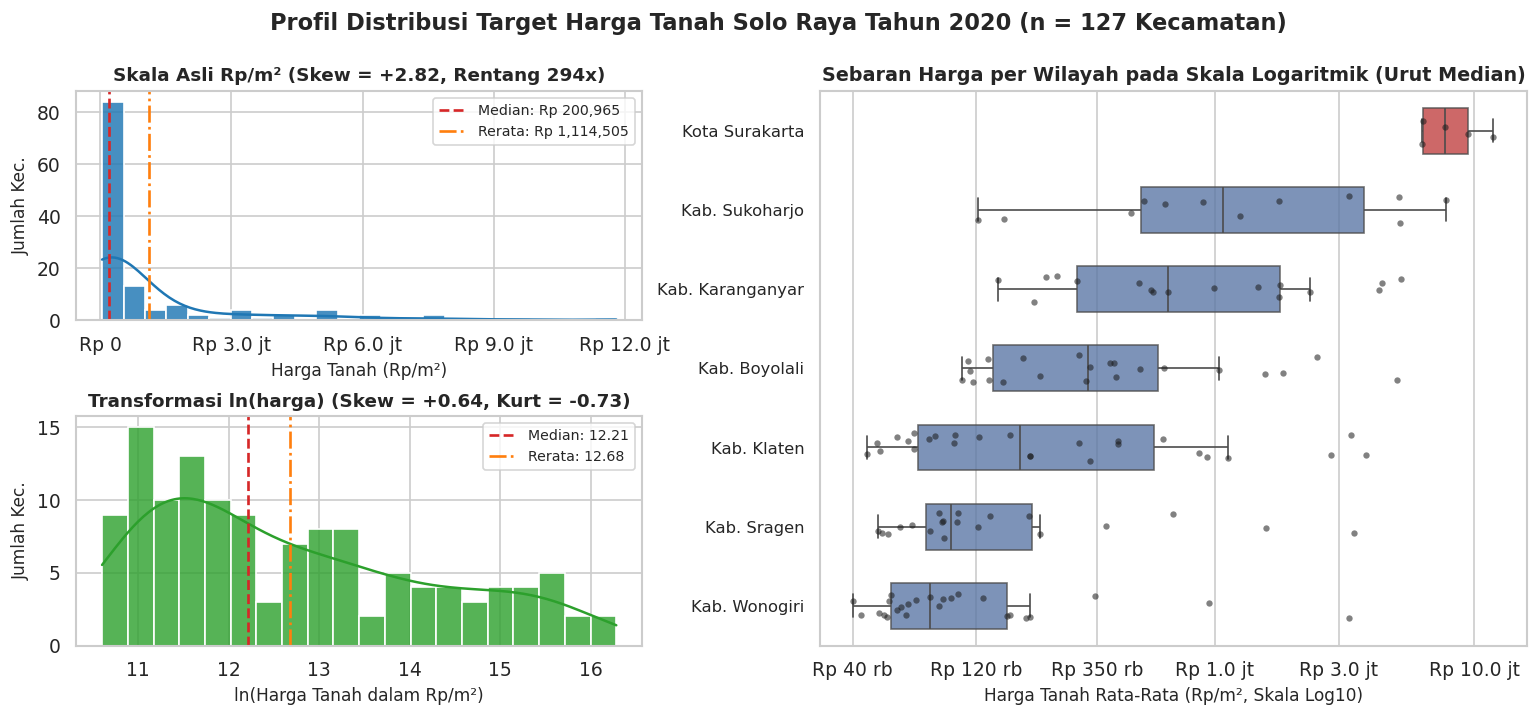

Tersimpan: figures/presentasi_3_model/01_distribusi_harga_tanah.png


In [4]:
fig = plt.figure(figsize=(15.6, 6.0))
gs = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.25], height_ratios=[1.0, 1.0], hspace=0.42, wspace=0.28)

ax_lin = fig.add_subplot(gs[0, 0])
ax_log = fig.add_subplot(gs[1, 0])
ax_box = fig.add_subplot(gs[:, 1])

# Panel kiri atas: Histogram skala linear Rp/m²
sns.histplot(df[TARGET_COL], bins=24, kde=True, color="#1f77b4", edgecolor="white", alpha=0.82, ax=ax_lin)
med_val = float(df[TARGET_COL].median())
mean_val = float(df[TARGET_COL].mean())
ax_lin.axvline(med_val, color="#d62728", linestyle="--", linewidth=1.6, label=f"Median: Rp {med_val:,.0f}")
ax_lin.axvline(mean_val, color="#ff7f0e", linestyle="-.", linewidth=1.6, label=f"Rerata: Rp {mean_val:,.0f}")
ax_lin.xaxis.set_major_locator(mticker.MultipleLocator(3_000_000))
ax_lin.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
ax_lin.set_title(f"Skala Asli Rp/m² (Skew = {df[TARGET_COL].skew():+.2f}, Rentang 294x)", fontsize=11.0)
ax_lin.set_xlabel("Harga Tanah (Rp/m²)")
ax_lin.set_ylabel("Jumlah Kec.")
ax_lin.legend(frameon=True, fontsize=8.5, loc="upper right")

# Panel kiri bawah: Histogram ln(y)
ln_vals = np.log(df[TARGET_COL].to_numpy(dtype=float))
sns.histplot(ln_vals, bins=20, kde=True, color="#2ca02c", edgecolor="white", alpha=0.80, ax=ax_log)
ax_log.axvline(float(np.median(ln_vals)), color="#d62728", linestyle="--", linewidth=1.6, label=f"Median: {np.median(ln_vals):.2f}")
ax_log.axvline(float(np.mean(ln_vals)), color="#ff7f0e", linestyle="-.", linewidth=1.6, label=f"Rerata: {np.mean(ln_vals):.2f}")
ax_log.set_title(f"Transformasi ln(harga) (Skew = {pd.Series(ln_vals).skew():+.2f}, Kurt = {pd.Series(ln_vals).kurt():+.2f})", fontsize=11.0)
ax_log.set_xlabel("ln(Harga Tanah dalam Rp/m²)")
ax_log.set_ylabel("Jumlah Kec.")
ax_log.legend(frameon=True, fontsize=8.5, loc="upper right")

# Panel kanan: Boxplot + Strip pada skala log10 agar seluruh 7 wilayah terbaca jelas
order_kab = df.groupby("kab_kota")[TARGET_COL].median().sort_values(ascending=False).index.tolist()
palette_kab = ["#d62728" if k == "Kota Surakarta" else "#4c72b0" for k in order_kab]
sns.boxplot(
    data=df,
    y="kab_kota",
    x=TARGET_COL,
    order=order_kab,
    hue="kab_kota",
    palette=palette_kab,
    legend=False,
    width=0.58,
    showfliers=False,
    boxprops={"alpha": 0.78},
    ax=ax_box,
)
np.random.seed(42)  # jitter deterministik (seed=42)
sns.stripplot(
    data=df,
    y="kab_kota",
    x=TARGET_COL,
    order=order_kab,
    color="#1a1a1a",
    size=3.8,
    alpha=0.55,
    jitter=0.18,
    ax=ax_box,
)
ax_box.set_xscale("log")
log_ticks = [40_000, 120_000, 350_000, 1_000_000, 3_000_000, 10_000_000]
ax_box.set_xticks(log_ticks)
ax_box.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
ax_box.xaxis.set_minor_formatter(mticker.NullFormatter())
ax_box.set_xlim(30_000, 16_000_000)
ax_box.set_yticks(range(len(order_kab)))
ax_box.set_yticklabels([k.replace("Kabupaten ", "Kab. ") for k in order_kab], fontsize=9.8)
ax_box.set_title("Sebaran Harga per Wilayah pada Skala Logaritmik (Urut Median)", fontsize=11.5)
ax_box.set_xlabel("Harga Tanah Rata-Rata (Rp/m², Skala Log10)")
ax_box.set_ylabel("")

fig.suptitle("Profil Distribusi Target Harga Tanah Solo Raya Tahun 2020 (n = 127 Kecamatan)", fontsize=13.5, fontweight="bold", y=0.99)
out1 = FIG_DIR / "01_distribusi_harga_tanah.png"
fig.savefig(out1, dpi=220, bbox_inches="tight")
plt.show()
print("Tersimpan:", out1.relative_to(ROOT))

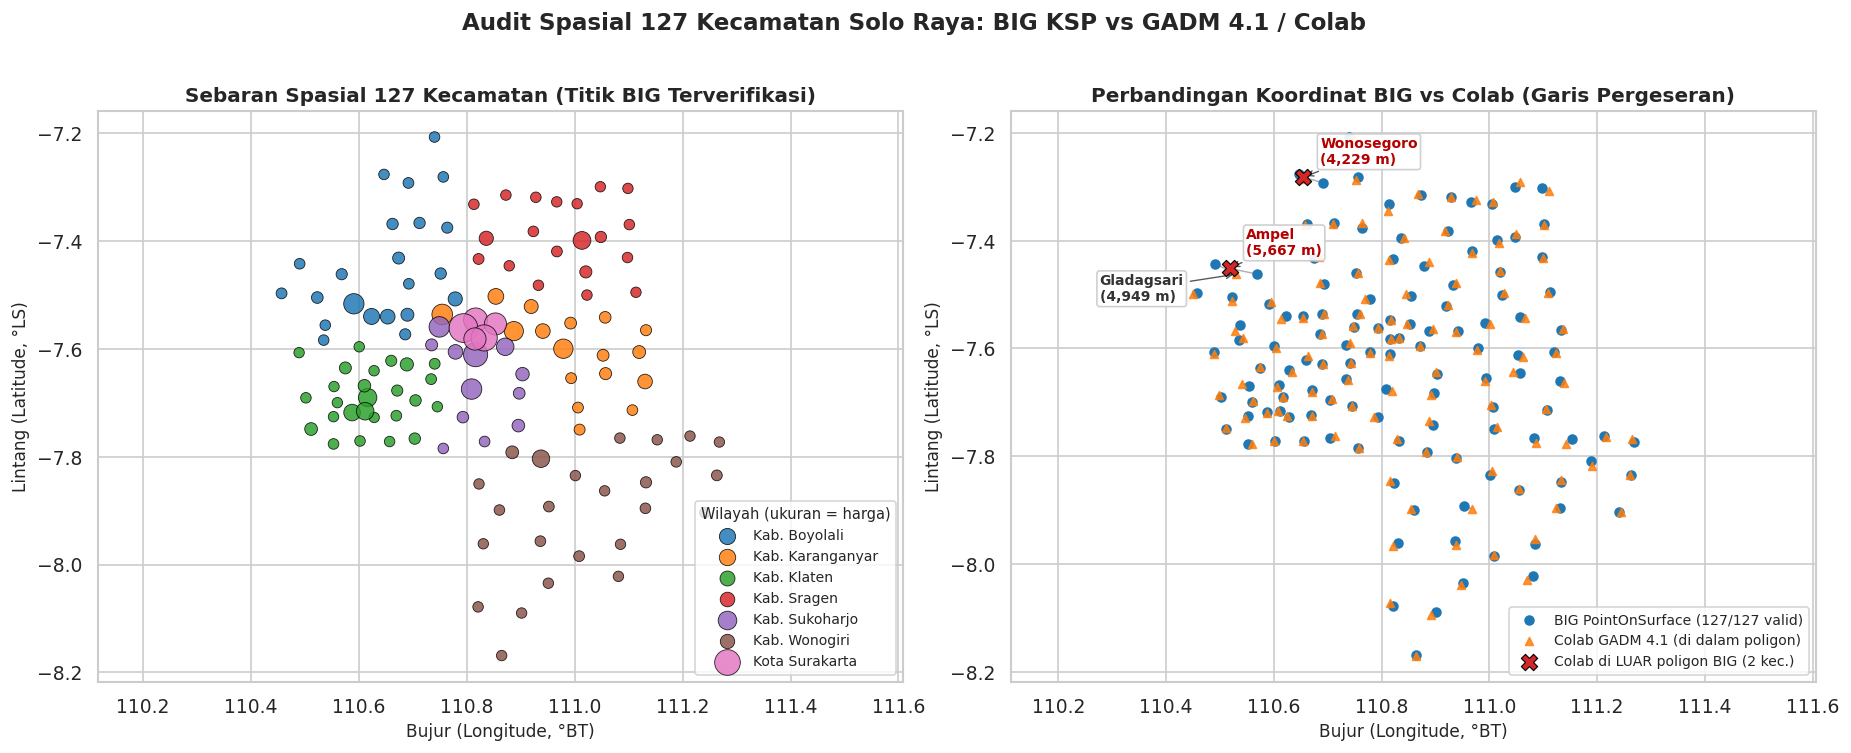

Tersimpan: figures/presentasi_3_model/02_peta_sebaran_dan_selisih_koordinat.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15.4, 6.2))

# Panel kiri: Peta sebaran 127 kecamatan menurut kab_kota & skala harga
ax = axes[0]
kab_list = sorted(df["kab_kota"].unique())
cmap_kab = dict(zip(kab_list, sns.color_palette("tab10", len(kab_list))))
for kab in kab_list:
    sub = df[df["kab_kota"] == kab]
    ax.scatter(
        sub["lon"],
        sub["lat"],
        s=38 + 260 * (sub[TARGET_COL] / df[TARGET_COL].max()),
        color=cmap_kab[kab],
        alpha=0.84,
        edgecolors="black",
        linewidths=0.5,
        label=kab.replace("Kabupaten ", "Kab. "),
    )
ax.set_title("Sebaran Spasial 127 Kecamatan (Titik BIG Terverifikasi)")
ax.set_xlabel("Bujur (Longitude, °BT)")
ax.set_ylabel("Lintang (Latitude, °LS)")
ax.legend(title="Wilayah (ukuran = harga)", loc="lower right", fontsize=8.4, title_fontsize=8.8, frameon=True)
ax.set_aspect("equal", adjustable="datalim")

# Panel kanan: Vektor pergeseran BIG vs Colab + sorotan titik di luar poligon BIG
ax = axes[1]
in_poly = df_audit[df_audit["colab_di_dalam_poligon"]]
out_poly = df_audit[~df_audit["colab_di_dalam_poligon"]]

for r in df_audit.itertuples(index=False):
    ax.plot([r.lon_big, r.lon_colab], [r.lat_big, r.lat_colab], color="#7f7f7f", linewidth=0.9, alpha=0.6, zorder=1)

ax.scatter(df_audit["lon_big"], df_audit["lat_big"], s=28, color="#1f77b4", label="BIG PointOnSurface (127/127 valid)", zorder=2)
ax.scatter(in_poly["lon_colab"], in_poly["lat_colab"], s=22, marker="^", color="#ff7f0e", alpha=0.82, label="Colab GADM 4.1 (di dalam poligon)", zorder=3)
ax.scatter(out_poly["lon_colab"], out_poly["lat_colab"], s=95, marker="X", color="#d62728", edgecolors="black", linewidths=0.7, label="Colab di LUAR poligon BIG (2 kec.)", zorder=4)

highlight_names = {"Ampel", "Gladagsari", "Wonosegoro"}
for r in df_audit[df_audit["kecamatan"].isin(highlight_names)].itertuples(index=False):
    offset_xy = (10, 8) if r.kecamatan != "Gladagsari" else (-82, -16)
    ax.annotate(
        f"{r.kecamatan}\n({r.selisih_big_vs_colab_m:,.0f} m)",
        xy=(r.lon_colab, r.lat_colab),
        xytext=offset_xy,
        textcoords="offset points",
        fontsize=8.3,
        fontweight="bold",
        color="#b30000" if not r.colab_di_dalam_poligon else "#333333",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#cccccc", alpha=0.92),
        arrowprops=dict(arrowstyle="->", color="#555555", lw=0.8),
    )

ax.set_title("Perbandingan Koordinat BIG vs Colab (Garis Pergeseran)")
ax.set_xlabel("Bujur (Longitude, °BT)")
ax.set_ylabel("Lintang (Latitude, °LS)")
ax.legend(loc="lower right", fontsize=8.4, frameon=True)
ax.set_aspect("equal", adjustable="datalim")

fig.suptitle("Audit Spasial 127 Kecamatan Solo Raya: BIG KSP vs GADM 4.1 / Colab", fontsize=13.8, fontweight="bold", y=1.01)
fig.tight_layout()
out2 = FIG_DIR / "02_peta_sebaran_dan_selisih_koordinat.png"
fig.savefig(out2, dpi=220, bbox_inches="tight")
plt.show()
print("Tersimpan:", out2.relative_to(ROOT))

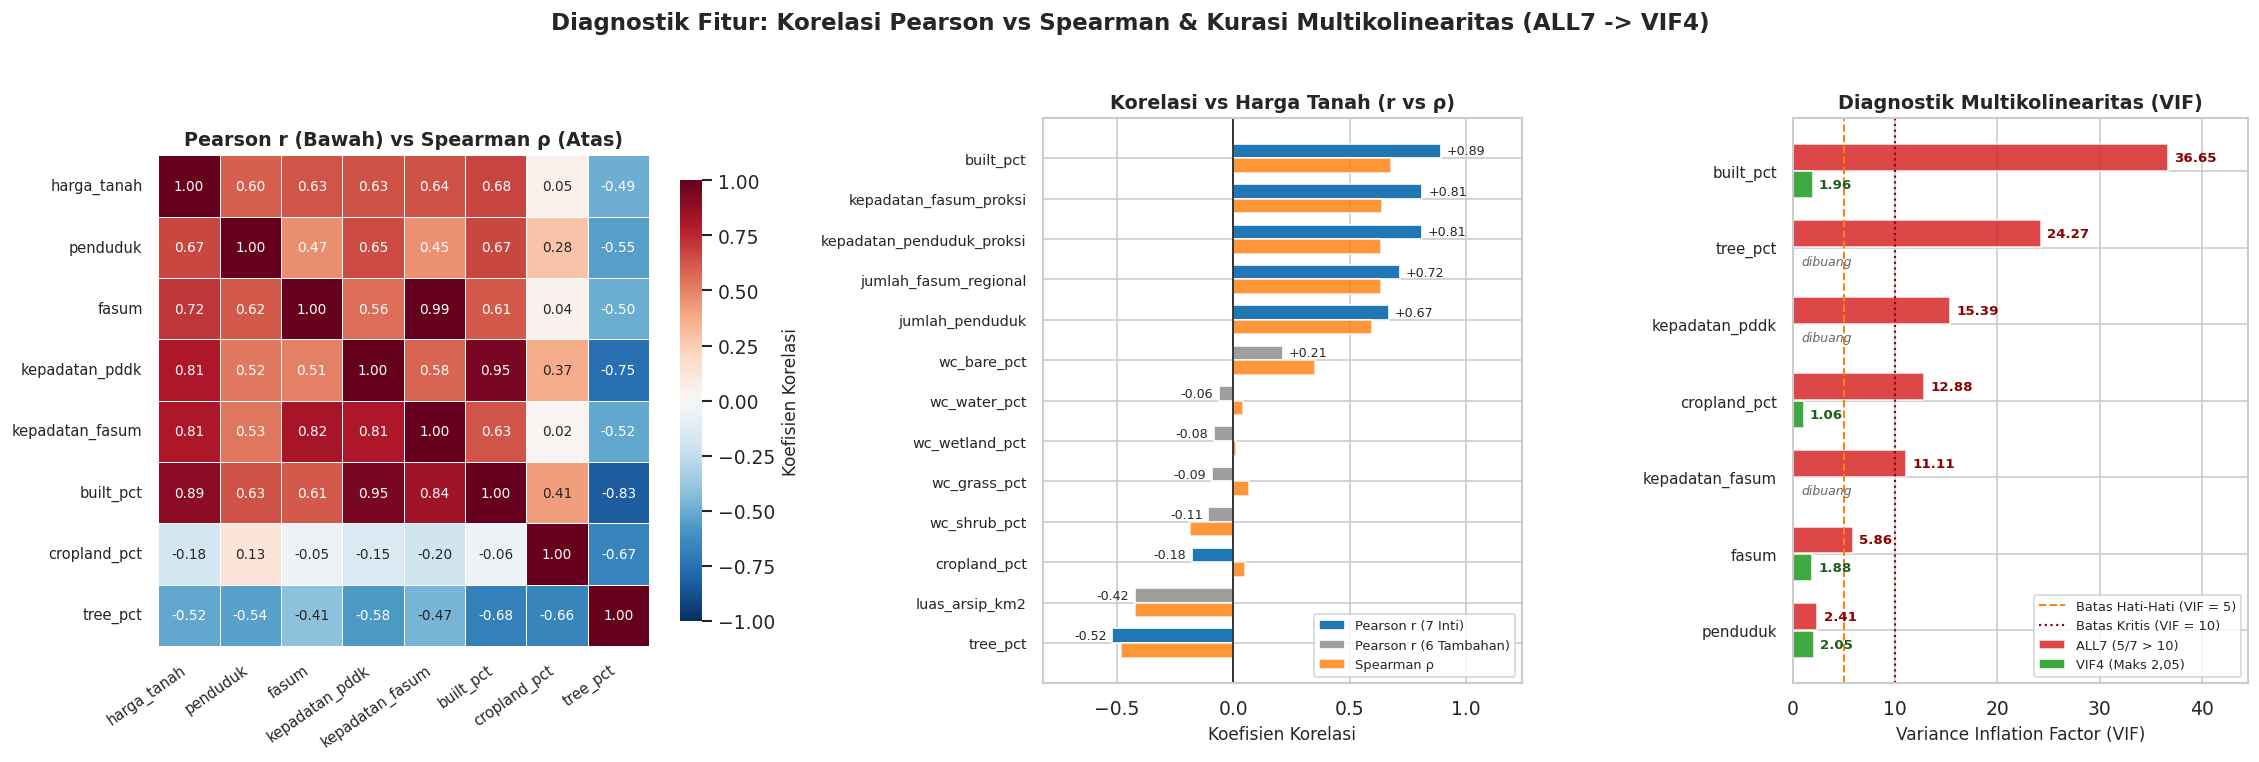

Tersimpan: figures/presentasi_3_model/03_matriks_korelasi_fitur.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19.0, 6.2), gridspec_kw={"width_ratios": [1.28, 1.0, 0.95]})

# Panel 1: Matriks gabungan Pearson r (segitiga bawah) vs Spearman rho (segitiga atas)
cols_heat = [TARGET_COL] + ALL7_FEATURES
short_names = {
    TARGET_COL: "harga_tanah",
    "jumlah_penduduk": "penduduk",
    "jumlah_fasum_regional": "fasum",
    "kepadatan_penduduk_proksi": "kepadatan_pddk",
    "kepadatan_fasum_proksi": "kepadatan_fasum",
    "built_pct": "built_pct",
    "cropland_pct": "cropland_pct",
    "tree_pct": "tree_pct",
}
pearson_mat = df[cols_heat].corr(method="pearson").rename(index=short_names, columns=short_names)
spearman_mat = spearman_matrix_scratch(df[cols_heat]).rename(index=short_names, columns=short_names)
combined_mat = pearson_mat.copy()
n_m = len(cols_heat)
for i in range(n_m):
    for j in range(i + 1, n_m):
        combined_mat.iloc[i, j] = spearman_mat.iloc[i, j]

sns.heatmap(
    combined_mat,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.6,
    annot_kws={"size": 8.2},
    cbar_kws={"shrink": 0.78, "label": "Koefisien Korelasi"},
    ax=axes[0],
)
axes[0].set_title("Pearson r (Bawah) vs Spearman ρ (Atas)", fontsize=11.5)
plt.setp(axes[0].get_xticklabels(), rotation=35, ha="right", fontsize=8.8)
plt.setp(axes[0].get_yticklabels(), fontsize=8.8)

# Panel 2: Perbandingan Pearson r vs Spearman rho terhadap Target (13 fitur)
all_num_feats = ALL7_FEATURES + AUX_FEATURES
r_vs_y = df[all_num_feats].corrwith(df[TARGET_COL])
rho_vs_y = pd.Series({f: spearman_corr_scratch(df[f], df[TARGET_COL]) for f in all_num_feats})
order_f = r_vs_y.sort_values().index.tolist()
y_pos = np.arange(len(order_f))
bar_h = 0.36

colors_r = ["#1f77b4" if f in ALL7_FEATURES else "#9e9e9e" for f in order_f]
axes[1].barh(y_pos + bar_h / 2, [r_vs_y[f] for f in order_f], height=bar_h, color=colors_r, edgecolor="white", label="Pearson r")
axes[1].barh(y_pos - bar_h / 2, [rho_vs_y[f] for f in order_f], height=bar_h, color="#ff7f0e", alpha=0.82, edgecolor="white", label="Spearman ρ")
axes[1].axvline(0, color="black", linewidth=0.9)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(order_f, fontsize=8.6)
axes[1].set_xlim(-0.82, 1.24)
axes[1].set_title("Korelasi vs Harga Tanah (r vs ρ)", fontsize=11.5)
axes[1].set_xlabel("Koefisien Korelasi")
for i, f in enumerate(order_f):
    rv = r_vs_y[f]
    ha = "left" if rv >= 0 else "right"
    dx = 0.025 if rv >= 0 else -0.025
    axes[1].text(rv + dx, i + bar_h / 2, f"{rv:+.2f}", va="center", ha=ha, fontsize=7.6)
legend_p2 = [
    Patch(facecolor="#1f77b4", label="Pearson r (7 Inti)"),
    Patch(facecolor="#9e9e9e", label="Pearson r (6 Tambahan)"),
    Patch(facecolor="#ff7f0e", alpha=0.82, label="Spearman ρ"),
]
axes[1].legend(handles=legend_p2, loc="lower right", fontsize=7.8, frameon=True)

# Panel 3: Horizontal Barplot VIF (ALL7 vs VIF4)
vif_order = sorted(ALL7_FEATURES, key=lambda c: vif_all7[c])
y_v = np.arange(len(vif_order))
vals_all7 = [vif_all7[f] for f in vif_order]
vals_vif4 = [vif_vif4.get(f, 0.0) for f in vif_order]

axes[2].barh(y_v + 0.18, vals_all7, height=0.35, color="#d62728", alpha=0.85, edgecolor="white", label="ALL7 (5/7 > 10)")
axes[2].barh(y_v - 0.18, vals_vif4, height=0.35, color="#2ca02c", alpha=0.90, edgecolor="white", label="VIF4 (Maks 2,05)")
axes[2].axvline(5.0, color="#ff7f0e", linestyle="--", linewidth=1.2, label="Batas Hati-Hati (VIF = 5)")
axes[2].axvline(10.0, color="#8b0000", linestyle=":", linewidth=1.3, label="Batas Kritis (VIF = 10)")
axes[2].set_yticks(y_v)
axes[2].set_yticklabels([short_names[f] for f in vif_order], fontsize=9.0)
axes[2].set_xlim(0, 44.5)
axes[2].set_title("Diagnostik Multikolinearitas (VIF)", fontsize=11.5)
axes[2].set_xlabel("Variance Inflation Factor (VIF)")
for i, (va7, vf4, fname) in enumerate(zip(vals_all7, vals_vif4, vif_order)):
    axes[2].text(va7 + 0.6, i + 0.18, f"{va7:.2f}", va="center", ha="left", fontsize=8.0, color="#8b0000", fontweight="bold")
    if fname in VIF4_FEATURES:
        axes[2].text(vf4 + 0.6, i - 0.18, f"{vf4:.2f}", va="center", ha="left", fontsize=8.0, color="#1b5e20", fontweight="bold")
    else:
        axes[2].text(0.8, i - 0.18, "dibuang", va="center", ha="left", fontsize=7.5, color="#666666", style="italic")
axes[2].legend(loc="lower right", fontsize=7.8, frameon=True)

fig.suptitle("Diagnostik Fitur: Korelasi Pearson vs Spearman & Kurasi Multikolinearitas (ALL7 -> VIF4)", fontsize=13.8, fontweight="bold", y=1.02)
fig.tight_layout()
out3 = FIG_DIR / "03_matriks_korelasi_fitur.png"
fig.savefig(out3, dpi=220, bbox_inches="tight")
plt.show()
print("Tersimpan:", out3.relative_to(ROOT))

## 4. Implementasi 3 Algoritma Default *From Scratch* & Metrik Evaluasi

Ketiga model dibangun 100% dari nol (`numpy` dan `math`) tanpa tuning hyperparameter:

1. **Geographically Weighted Regression (`GWRRegressorScratch`)**:
   - Menggunakan jarak **Haversine** ($R = 6.371{,}0088\text{ km}$) dan *kernel* klasik **Fixed Gaussian** ($w_{ij} = \exp(-0{,}5 (d_{ij}/h)^2)$) dengan `bandwidth=20.0` km, `adaptive=False`, dan stabilisasi numerik `reg_lambda=1e-6`.
   - **Perbaikan Kritis Penalti Intersep**: Penalti Ridge kecil $\lambda$ **tidak diterapkan pada intersep $\beta_0$** (`penalty[0, 0] = 0.0`), sehingga sistem lokal $(X_w^T X_w + \lambda P)\beta = X_w^T y_w$ diselesaikan via `np.linalg.solve` (dengan *fallback* `np.linalg.lstsq` bila matriks singular) tanpa mengecilkan intersep harga dasar. Setiap titik uji juga mencatat **local Condition Number** `cond(X_w)` (ambang Belsley `> 30`) serta **bobot efektif** $\sum w_i$.
   - **Klarifikasi Literatur (*Fixed* vs *Adaptive Default*)**: Dalam pustaka `mgwr` (Oshan et al., 2019), varian default-nya adalah *adaptive bisquare* dengan seleksi bandwidth `Sel_BW`; sedangkan konfigurasi `bw=20.0 km` Fixed Gaussian di sini adalah **baseline skala lokal klasik** (Fotheringham et al., 2002) yang konsisten dengan kerangka tugas tanpa *tuning*. Di wilayah pinggiran selatan seperti Wonogiri, jarak antar-kecamatan antar-lipatan mencapai **`44,25 km`**, sehingga $\sum w$ menyusut hingga **`0,949`**.

2. **K-Nearest Neighbors (`KNNRegressorScratch`)**:
   - Jarak Euclidean pada fitur terstandardisasi Z-score dengan parameter default `k=5` dan `weights="uniform"` (sepadan dengan default `KNeighborsRegressor` pada `scikit-learn`).

3. **Decision Tree (`DecisionTreeRegressorScratch`)**:
   - Algoritma **CART** (*Classification and Regression Tree*) dengan kriteria **MSE** dan parameter default tanpa pemangkasan: `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1` (sepadan dengan default `DecisionTreeRegressor`).
   - **Invariansi Skala**: Pohon keputusan berbasis ambang monotonik bersifat **invarian terhadap penskalaan linear Z-score** (berbeda dari GWR & KNN yang sangat bergantung pada standardisasi fitur). Pada data latih berukuran $n \approx 101\text{–}122$, CART tak terbatas menghasilkan daun murni (`n_leaves == n_train`, kedalaman `13–16`), yang kami catat secara eksplisit.

### Metrik Evaluasi Komprehensif (`Rp/m²`)
Karena harga tanah sangat menceng ke kanan (`294×`), `MAPE (%)` sangat rentan terdistorsi oleh penyebut kecil di kecamatan pedesaan (`Rp 40 rb–80 rb/m²`) (Hyndman & Koehler, 2006). Oleh sebab itu, notebook melaporkan **MAE**, **MdAE** (median galat absolut yang tahan *outlier*), **RMSE** (sensitif galat besar, Chai & Draxler, 2014), **$R^2$**, **WAPE (%)** ($\sum |y-\hat{y}|/\sum y$), **MAPE (%)**, **Bias / ME** ($\text{mean}(\hat{y} - y)$), **RMSLE** (pada prediksi positif $\hat{y} > 0$ dengan mencatat jumlah titik terpotong), jumlah **`Prediksi < 0`** tidak fisik, serta **Global Moran's I Residu** (`p_sim`) untuk mengecek sisa autokorelasi spasial.

In [7]:
# ==============================================================================
# STANDARDISASI, METRIK EVALUASI, & 3 MODEL DEFAULT FROM SCRATCH
# ==============================================================================

def fit_standardizer(X):
    """Menghitung mean dan std (ddof=0) HANYA dari data latih."""
    X = np.asarray(X, dtype=float)
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0, ddof=0)
    std = np.where(std == 0.0, 1.0, std)
    return mean, std


def apply_standardizer(X, mean, std):
    return (np.asarray(X, dtype=float) - mean) / std


def mae_scratch(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float))))


def mdae_scratch(y_true, y_pred):
    return float(np.median(np.abs(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float))))


def rmse_scratch(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)) ** 2)))


def r2_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    return 1.0 - (ss_res / ss_tot) if ss_tot != 0.0 else 0.0


def wape_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = float(np.sum(np.abs(y_true)))
    return float(np.sum(np.abs(y_true - y_pred)) / denom * 100.0) if denom > 0.0 else 0.0


def mape_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0.0
    if not np.any(mask):
        return 0.0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100.0)


def bias_scratch(y_true, y_pred):
    """Mean Error (y_hat - y): negatif berarti rata-rata under-prediction."""
    return float(np.mean(np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)))


def rmsle_positive_scratch(y_true, y_pred):
    """RMSLE pada prediksi positif (y_hat > 0) disertai jumlah titik negatif yang dikecualikan."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    pos_mask = y_pred > 0.0
    n_clipped = int(np.sum(~pos_mask))
    if not np.any(pos_mask):
        return float("nan"), n_clipped
    rmsle_val = float(np.sqrt(np.mean((np.log1p(y_true[pos_mask]) - np.log1p(y_pred[pos_mask])) ** 2)))
    return rmsle_val, n_clipped


def evaluate_predictions_scratch(y_true, y_pred, coords_sub=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmsle_val, n_clipped = rmsle_positive_scratch(y_true, y_pred)
    W_use = W_knn5 if coords_sub is None else build_knn_weights_scratch(coords_sub, k=5)
    I_res, _, p_res = morans_i_scratch(y_true - y_pred, W_use, n_perm=999, seed=42)
    return {
        "MAE (Rp/m²)": mae_scratch(y_true, y_pred),
        "MdAE (Rp/m²)": mdae_scratch(y_true, y_pred),
        "RMSE (Rp/m²)": rmse_scratch(y_true, y_pred),
        "R²": r2_scratch(y_true, y_pred),
        "WAPE (%)": wape_scratch(y_true, y_pred),
        "MAPE (%)": mape_scratch(y_true, y_pred),
        "Bias / ME (Rp/m²)": bias_scratch(y_true, y_pred),
        "RMSLE (ŷ>0)": rmsle_val,
        "RMSLE_clipped": n_clipped,
        "Prediksi < 0": int(np.sum(y_pred < 0.0)),
        "Moran I Residu": I_res,
        "p_sim Moran": p_res,
    }


# ==============================================================================
# 1. GWR REGRESSOR (CLASSIC FIXED GAUSSIAN, INTERCEPT UNPENALIZED)
# ==============================================================================
class GWRRegressorScratch:
    def __init__(self, bandwidth=20.0, kernel="gaussian", adaptive=False, reg_lambda=1e-6):
        self.bandwidth = bandwidth
        self.kernel = kernel
        self.adaptive = adaptive
        self.reg_lambda = reg_lambda
        self.X_train = None
        self.y_train = None
        self.coords_train = None

    def _kernel_weights(self, dists):
        if self.adaptive:
            k_nn = int(min(max(2, round(self.bandwidth)), len(dists)))
            h = max(float(np.sort(dists)[k_nn - 1]) * 1.000001, 1e-6)
        else:
            h = max(float(self.bandwidth), 1e-6)

        if self.kernel == "gaussian":
            w = np.exp(-0.5 * (dists / h) ** 2)
        elif self.kernel == "bisquare":
            w = np.where(dists < h, (1.0 - (dists / h) ** 2) ** 2, 0.0)
        else:
            raise ValueError(f"Kernel tidak dikenal: {self.kernel}")

        if np.sum(w) <= 1e-12:
            return np.ones_like(w)
        return w

    def fit(self, X, y, coords):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=float)
        self.coords_train = np.asarray(coords, dtype=float)
        return self

    def predict(self, X, coords, return_diagnostics=False):
        X_test = np.asarray(X, dtype=float)
        coords_test = np.asarray(coords, dtype=float)
        X_des_train = np.column_stack([np.ones(self.X_train.shape[0]), self.X_train])
        X_des_test = np.column_stack([np.ones(X_test.shape[0]), X_test])

        dist_matrix = haversine_km(
            coords_test[:, 0], coords_test[:, 1],
            self.coords_train[:, 0], self.coords_train[:, 1],
        )

        preds = np.zeros(X_test.shape[0], dtype=float)
        cond_xw = np.zeros(X_test.shape[0], dtype=float)
        cond_xtwx = np.zeros(X_test.shape[0], dtype=float)
        sum_w = np.zeros(X_test.shape[0], dtype=float)
        min_dist_km = np.zeros(X_test.shape[0], dtype=float)

        n_params = X_des_train.shape[1]
        penalty = np.eye(n_params)
        penalty[0, 0] = 0.0  # Intersep beta_0 TIDAK dipenalisasi
        reg_eye = self.reg_lambda * penalty

        for i in range(X_test.shape[0]):
            w = self._kernel_weights(dist_matrix[i])
            sum_w[i] = float(np.sum(w))
            min_dist_km[i] = float(np.min(dist_matrix[i]))
            w_sqrt = np.sqrt(w)[:, None]
            X_w = X_des_train * w_sqrt
            y_w = self.y_train * w_sqrt.ravel()
            A = X_w.T @ X_w + reg_eye
            b = X_w.T @ y_w

            cond_xw[i] = float(np.linalg.cond(X_w))
            cond_xtwx[i] = float(np.linalg.cond(A))
            try:
                beta_local = np.linalg.solve(A, b)
            except np.linalg.LinAlgError:
                beta_local, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
            preds[i] = float(X_des_test[i] @ beta_local)

        if return_diagnostics:
            return preds, {
                "cond_xw": cond_xw,
                "cond_xtwx": cond_xtwx,
                "sum_w": sum_w,
                "min_dist_km": min_dist_km,
            }
        return preds


# ==============================================================================
# 2. KNN REGRESSOR (EUCLIDEAN, K=5, UNIFORM WEIGHTS DEFAULT)
# ==============================================================================
class KNNRegressorScratch:
    def __init__(self, k=5, weights="uniform", eps=1e-9):
        self.k = k
        self.weights = weights
        self.eps = eps
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=float)
        return self

    def predict(self, X):
        X_test = np.asarray(X, dtype=float)
        preds = np.zeros(X_test.shape[0], dtype=float)
        k_eff = min(self.k, len(self.y_train))
        for i, x_q in enumerate(X_test):
            dists = np.sqrt(np.sum((self.X_train - x_q) ** 2, axis=1))
            idx_k = np.argsort(dists)[:k_eff]
            d_k = dists[idx_k]
            y_k = self.y_train[idx_k]
            if self.weights == "uniform":
                preds[i] = float(np.mean(y_k))
            elif self.weights == "distance":
                zero_mask = d_k <= self.eps
                if np.any(zero_mask):
                    preds[i] = float(np.mean(y_k[zero_mask]))
                else:
                    w = 1.0 / d_k
                    preds[i] = float(np.sum(w * y_k) / np.sum(w))
            else:
                raise ValueError(f"Jenis bobot tidak dikenal: {self.weights}")
        return preds


# ==============================================================================
# 3. DECISION TREE REGRESSOR (CART MSE DEFAULT UNCONSTRAINED)
# ==============================================================================
class DecisionTreeRegressorScratch:
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None
        self.fitted_depth_ = 0
        self.n_leaves_ = 0

    @staticmethod
    def _mse(y):
        if len(y) == 0:
            return 0.0
        return float(np.mean((y - np.mean(y)) ** 2))

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        parent_mse = self._mse(y)
        best_gain = -1.0
        best_feat = None
        best_thresh = None
        for feat in range(n_features):
            vals = np.unique(X[:, feat])
            if len(vals) <= 1:
                continue
            thresholds = (vals[:-1] + vals[1:]) / 2.0
            for thresh in thresholds:
                left_mask = X[:, feat] <= thresh
                n_l = int(np.sum(left_mask))
                n_r = n_samples - n_l
                if n_l < self.min_samples_leaf or n_r < self.min_samples_leaf:
                    continue
                child_mse = (n_l / n_samples) * self._mse(y[left_mask]) + (n_r / n_samples) * self._mse(y[~left_mask])
                gain = parent_mse - child_mse
                if gain > best_gain:
                    best_gain = gain
                    best_feat = feat
                    best_thresh = float(thresh)
        return best_feat, best_thresh, best_gain

    def _build_tree(self, X, y, depth):
        self.fitted_depth_ = max(self.fitted_depth_, depth)
        leaf_val = float(np.mean(y))
        depth_limit_hit = self.max_depth is not None and depth >= self.max_depth
        if depth_limit_hit or len(y) < self.min_samples_split or np.std(y) == 0.0:
            self.n_leaves_ += 1
            return {"is_leaf": True, "value": leaf_val}
        feat, thresh, gain = self._best_split(X, y)
        if feat is None or gain <= 0.0:
            self.n_leaves_ += 1
            return {"is_leaf": True, "value": leaf_val}
        left_mask = X[:, feat] <= thresh
        return {
            "is_leaf": False,
            "feature": feat,
            "threshold": thresh,
            "left": self._build_tree(X[left_mask], y[left_mask], depth + 1),
            "right": self._build_tree(X[~left_mask], y[~left_mask], depth + 1),
        }

    def fit(self, X, y):
        self.fitted_depth_ = 0
        self.n_leaves_ = 0
        self.root = self._build_tree(np.asarray(X, dtype=float), np.asarray(y, dtype=float), depth=0)
        return self

    def _predict_row(self, row, node):
        if node["is_leaf"]:
            return node["value"]
        if row[node["feature"]] <= node["threshold"]:
            return self._predict_row(row, node["left"])
        return self._predict_row(row, node["right"])

    def predict(self, X):
        return np.array([self._predict_row(row, self.root) for row in np.asarray(X, dtype=float)], dtype=float)


print("Utilitas evaluasi & ketiga kelas model default from scratch siap digunakan.")

Utilitas evaluasi & ketiga kelas model default from scratch siap digunakan.


## 5. Evaluasi Utama: LOKO 7-Fold CV pada Fitur Non-Kolinear (`VIF4`, Skala `Rp/m²`)

Sesuai hasil audit kolinearitas Bagian 2, evaluasi utama membandingkan ketiga model default pada himpunan fitur non-kolinear **`VIF4`** (`built_pct`, `cropland_pct`, `jumlah_penduduk`, `jumlah_fasum_regional`; maks VIF global = `2,05`, maks VIF seluruh lipatan latih = `2,64`) dengan target skala asli **`Rp/m²`**. Efek perbandingan langsung terhadap `ALL7`, transformasi $\ln(y)$ + *smearing* Duan (1983), serta Random 7-Fold CV disajikan pada Bagian 7.

> **Catatan Kritis**: Pada setiap lipatan LOKO, `fit_standardizer` dipanggil **hanya pada `train_mask`** (`101–122` kecamatan) agar nol informasi dari kabupaten/kota uji bocor ke proses pelatihan.

In [8]:
y_all = df[TARGET_COL].to_numpy(dtype=float)
assert np.isfinite(y_all).all()

MODEL_SPECS = [
    (
        "GWR (Fixed Gaussian, bw=20 km)",
        "GWR",
        lambda: GWRRegressorScratch(bandwidth=20.0, kernel="gaussian", adaptive=False, reg_lambda=1e-6),
        True,
    ),
    (
        "KNN (k=5, Euclidean, Uniform)",
        "KNN",
        lambda: KNNRegressorScratch(k=5, weights="uniform"),
        False,
    ),
    (
        "Decision Tree (CART MSE, Default)",
        "Decision Tree",
        lambda: DecisionTreeRegressorScratch(max_depth=None, min_samples_split=2, min_samples_leaf=1),
        False,
    ),
]

def run_loko_experiment(feature_cols, log_target=False, use_duan=False):
    X_mat = df[feature_cols].to_numpy(dtype=float)
    assert np.isfinite(X_mat).all(), "Terdapat NaN/Inf pada matriks fitur!"

    oof_preds = {}
    fold_rows = []
    gwr_diag = {
        "cond_xw": np.zeros(len(df)),
        "cond_xtwx": np.zeros(len(df)),
        "sum_w": np.zeros(len(df)),
        "min_dist_km": np.zeros(len(df)),
    }
    tree_logs = []

    for label_full, short_key, builder, needs_coords in MODEL_SPECS:
        preds_oof = np.full(len(df), np.nan, dtype=float)
        seen_test_count = 0

        for fold_idx, region in enumerate(regions):
            test_mask = groups == region
            train_mask = ~test_mask
            assert not np.any(train_mask & test_mask), "Kebocoran indeks latih–uji!"
            seen_test_count += int(np.sum(test_mask))

            # Standardisasi murni dari data latih
            mean_tr, std_tr = fit_standardizer(X_mat[train_mask])
            X_tr_std = apply_standardizer(X_mat[train_mask], mean_tr, std_tr)
            X_te_std = apply_standardizer(X_mat[test_mask], mean_tr, std_tr)
            y_tr_fit = np.log(y_all[train_mask]) if log_target else y_all[train_mask]

            model = builder()
            if needs_coords:
                model.fit(X_tr_std, y_tr_fit, coords_all[train_mask])
                y_hat_raw, dg = model.predict(X_te_std, coords_all[test_mask], return_diagnostics=True)
                for k in gwr_diag:
                    gwr_diag[k][test_mask] = dg[k]
            else:
                model.fit(X_tr_std, y_tr_fit)
                y_hat_raw = model.predict(X_te_std)

            if short_key == "Decision Tree":
                tree_logs.append({
                    "wilayah_uji": region,
                    "n_train": int(np.sum(train_mask)),
                    "max_depth": model.fitted_depth_,
                    "n_leaves": model.n_leaves_,
                })

            if log_target:
                if use_duan:
                    if needs_coords:
                        y_hat_tr = model.predict(X_tr_std, coords_all[train_mask])
                    else:
                        y_hat_tr = model.predict(X_tr_std)
                    # Faktor smearing Duan (1983) dihitung HANYA pada residu latih lipatan ini
                    smear_factor = float(np.mean(np.exp(y_tr_fit - y_hat_tr)))
                    y_hat = np.exp(y_hat_raw) * smear_factor
                else:
                    y_hat = np.exp(y_hat_raw)
            else:
                y_hat = y_hat_raw

            assert np.isfinite(y_hat).all(), f"Prediksi non-finite pada {short_key} - {region}"
            preds_oof[test_mask] = y_hat
            fold_rows.append({
                "model": label_full,
                "model_singkat": short_key,
                "wilayah_uji": region,
                "n_kecamatan": int(np.sum(test_mask)),
                "MAE_Rp_m2": mae_scratch(y_all[test_mask], y_hat),
                "MdAE_Rp_m2": mdae_scratch(y_all[test_mask], y_hat),
                "RMSE_Rp_m2": rmse_scratch(y_all[test_mask], y_hat),
                "R2": r2_scratch(y_all[test_mask], y_hat),
            })

        assert seen_test_count == 127, f"Jumlah prediksi uji bukan 127: {seen_test_count}"
        assert not np.isnan(preds_oof).any(), f"Terdapat NaN pada OOF {short_key}"
        oof_preds[short_key] = preds_oof

    return oof_preds, pd.DataFrame(fold_rows), gwr_diag, pd.DataFrame(tree_logs)

# Jalankan Evaluasi Utama: VIF4 + Skala Linear Rp/m²
oof_vif4, df_folds, gwr_diag_vif4, df_tree_log = run_loko_experiment(VIF4_FEATURES, log_target=False, use_duan=False)

pred_table = df[["kab_kota", "kecamatan", "lat", "lon", TARGET_COL]].copy()
summary_records = []
for label_full, short_key, _, _ in MODEL_SPECS:
    y_oof = oof_vif4[short_key]
    pred_table[f"pred_{short_key}"] = y_oof
    pred_table[f"err_{short_key}"] = np.abs(y_all - y_oof)
    pred_table[f"res_{short_key}"] = y_all - y_oof
    m_dict = evaluate_predictions_scratch(y_all, y_oof)
    summary_records.append({"Model": label_full, "Key": short_key, **m_dict})

df_summary = pd.DataFrame(summary_records).sort_values("MAE (Rp/m²)").reset_index(drop=True)
print("=== RINGKASAN UTAMA: 3 MODEL DEFAULT PADA VIF4 (127 KECAMATAN LOKO 7-FOLD CV) ===")
display(
    df_summary.style.format({
        "MAE (Rp/m²)": "{:,.0f}",
        "MdAE (Rp/m²)": "{:,.0f}",
        "RMSE (Rp/m²)": "{:,.0f}",
        "R²": "{:.4f}",
        "WAPE (%)": "{:.2f}%",
        "MAPE (%)": "{:.2f}%",
        "Bias / ME (Rp/m²)": "{:+,.0f}",
        "RMSLE (ŷ>0)": "{:.3f}",
        "Moran I Residu": "{:+.4f}",
        "p_sim Moran": "{:.3f}",
    })
)

# Diagnostik lokal GWR & eksposur prediksi negatif
pred_table["gwr_cond_xw"] = gwr_diag_vif4["cond_xw"]
pred_table["gwr_cond_xtwx"] = gwr_diag_vif4["cond_xtwx"]
pred_table["gwr_sum_w"] = gwr_diag_vif4["sum_w"]
pred_table["gwr_min_dist_km"] = gwr_diag_vif4["min_dist_km"]
neg_gwr = pred_table[pred_table["pred_GWR"] < 0.0][["kab_kota", "kecamatan", TARGET_COL, "pred_GWR", "gwr_sum_w", "gwr_cond_xw", "gwr_min_dist_km"]].sort_values("pred_GWR")

print(f"\n=== DIAGNOSTIK LOKAL GWR (VIF4) & EKSPOSUR PREDIKSI NEGATIF ({len(neg_gwr)}/127) ===")
print(
    f"cond(X_w) maks = {gwr_diag_vif4['cond_xw'].max():.2f} (titik > 30: {int((gwr_diag_vif4['cond_xw'] > 30).sum())}/127) | "
    f"cond(X_w^T X_w) maks = {gwr_diag_vif4['cond_xtwx'].max():.2f} | "
    f"min sum(w) = {gwr_diag_vif4['sum_w'].min():.3f} (jarak min ke latih maks = {gwr_diag_vif4['min_dist_km'].max():.2f} km)"
)
display(
    neg_gwr.head(8).style.format({
        TARGET_COL: "{:,.0f}",
        "pred_GWR": "{:+,.0f}",
        "gwr_sum_w": "{:.3f}",
        "gwr_cond_xw": "{:.2f}",
        "gwr_min_dist_km": "{:.2f} km",
    })
)

print("\n=== KOMPLEKSITAS DECISION TREE CART DEFAULT (MEMORISASI 100% DAUN MURNI) ===")
assert (df_tree_log["n_leaves"] == df_tree_log["n_train"]).all()
display(df_tree_log)

print("\n=== RINCIAN MAE (Rp/m²) PER KABUPATEN/KOTA (VIF4) ===")
pivot_mae = df_folds.pivot(index="wilayah_uji", columns="model_singkat", values="MAE_Rp_m2")[["GWR", "KNN", "Decision Tree"]]
display(pivot_mae.round(0).style.format("{:,.0f}"))

=== RINGKASAN UTAMA: 3 MODEL DEFAULT PADA VIF4 (127 KECAMATAN LOKO 7-FOLD CV) ===


,Model,Key,MAE (Rp/m²),MdAE (Rp/m²),RMSE (Rp/m²),R²,WAPE (%),MAPE (%),Bias / ME (Rp/m²),RMSLE (ŷ>0),RMSLE_clipped,Prediksi < 0,Moran I Residu,p_sim Moran
0,"KNN (k=5, Euclidean, Uniform)",KNN,"530,619","193,639","1,074,071",0.7218,47.61%,148.35%,"-281,401",1.067,0,0,+0.4649,0.001
1,"GWR (Fixed Gaussian, bw=20 km)",GWR,"581,272","347,595","976,740",0.7699,52.16%,252.94%,"+64,440",1.216,16,16,+0.1491,0.005
2,"Decision Tree (CART MSE, Default)",Decision Tree,"646,673","242,426","1,254,994",0.6201,58.02%,208.10%,"-112,257",1.312,0,0,+0.1300,0.013



=== DIAGNOSTIK LOKAL GWR (VIF4) & EKSPOSUR PREDIKSI NEGATIF (16/127) ===
cond(X_w) maks = 4.38 (titik > 30: 0/127) | cond(X_w^T X_w) maks = 19.17 | min sum(w) = 0.949 (jarak min ke latih maks = 44.25 km)


,kab_kota,kecamatan,harga_tanah_rata_rata_rp_m2,pred_GWR,gwr_sum_w,gwr_cond_xw,gwr_min_dist_km
25,Kabupaten Boyolali,Tamansari,"113,219","-384,779",24.971,2.77,5.64 km
77,Kabupaten Wonogiri,Paranggupito,"56,433","-369,193",0.949,2.43,44.25 km
63,Kabupaten Wonogiri,Wuryantoro,"101,854","-349,810",16.107,2.48,14.44 km
70,Kabupaten Wonogiri,Nguntoronadi,"161,244","-335,556",13.473,2.71,17.06 km
22,Kabupaten Boyolali,Selo,"211,352","-287,190",12.495,2.75,12.73 km
73,Kabupaten Wonogiri,Giritontro,"61,530","-276,190",2.386,2.28,36.14 km
68,Kabupaten Wonogiri,Manyaran,"59,332","-255,429",23.550,2.51,8.82 km
75,Kabupaten Wonogiri,Batuwarno,"192,857","-237,485",5.242,2.76,26.08 km



=== KOMPLEKSITAS DECISION TREE CART DEFAULT (MEMORISASI 100% DAUN MURNI) ===


,wilayah_uji,n_train,max_depth,n_leaves
0,Kabupaten Boyolali,105,14,105
1,Kabupaten Karanganyar,110,13,110
2,Kabupaten Klaten,101,14,101
3,Kabupaten Sragen,107,16,107
4,Kabupaten Sukoharjo,115,16,115
5,Kabupaten Wonogiri,102,16,102
6,Kota Surakarta,122,16,122



=== RINCIAN MAE (Rp/m²) PER KABUPATEN/KOTA (VIF4) ===


model_singkat,GWR,KNN,Decision Tree
wilayah_uji,,,
Kabupaten Boyolali,"419,816","380,491","638,536"
Kabupaten Karanganyar,"470,240","814,176","699,936"
Kabupaten Klaten,"607,725","323,036","585,397"
Kabupaten Sragen,"398,696","213,305","319,459"
Kabupaten Sukoharjo,"839,787","993,459","961,334"
Kabupaten Wonogiri,"338,605","173,995","208,929"
Kota Surakarta,"2,854,829","3,248,073","3,562,415"


## 6. Visualisasi Performa Utama, Diagnostik Residu, & Galat Spasial

Tiga figur berikut membandingkan performa komprehensif pada fitur terkurasi **`VIF4`**, menyorot prediksi negatif GWR serta pola residu (*Actual vs Predicted* & *Residuals vs Predicted*), dan memetakan autokorelasi galat spasial antarwilayah.

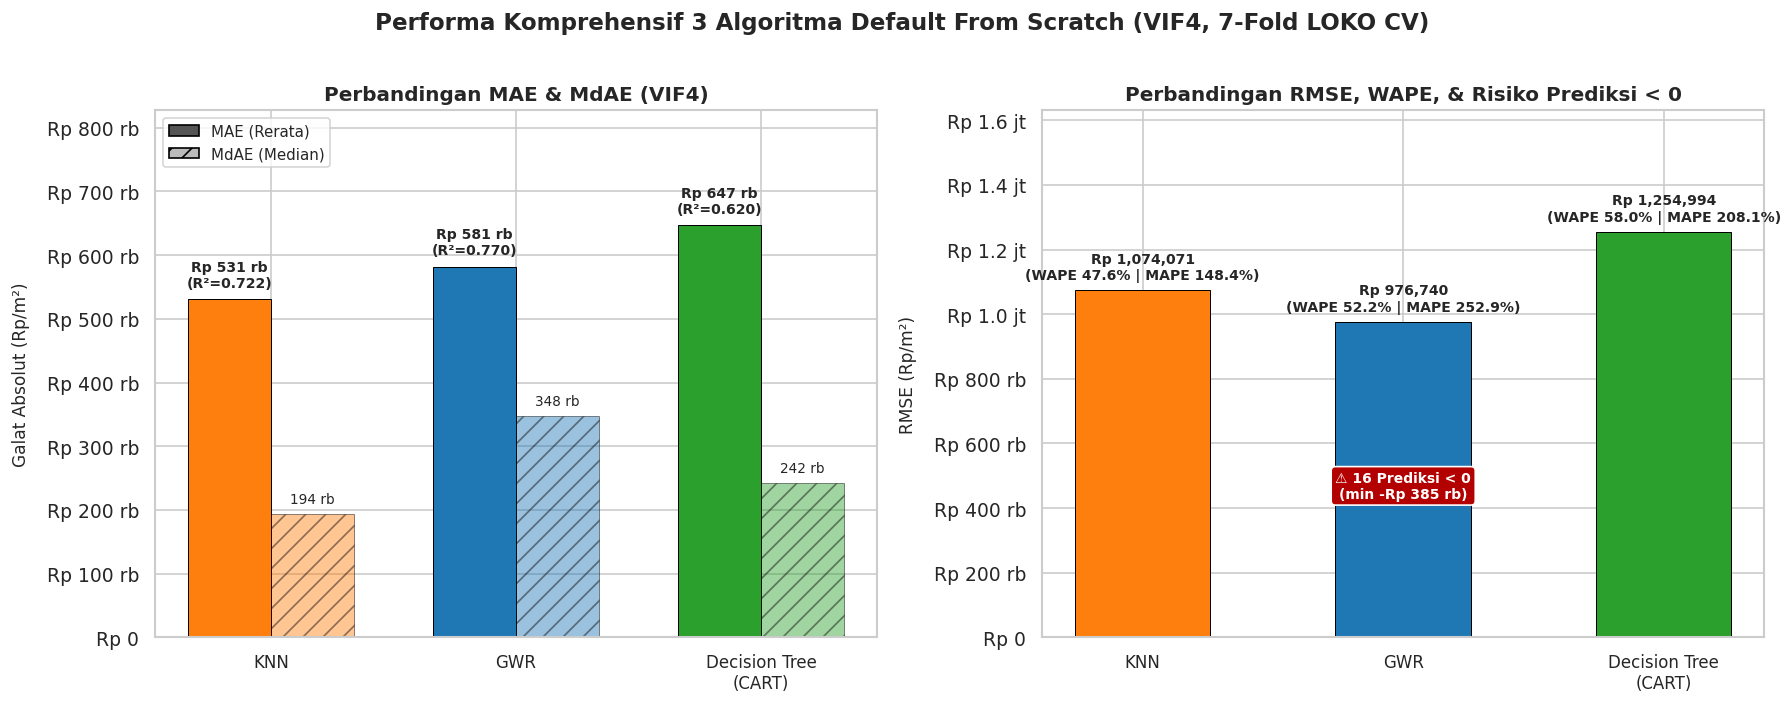

Tersimpan: figures/presentasi_3_model/04_perbandingan_mae_rmse_3_model.png


In [9]:
MODEL_COLORS = {
    "GWR": "#1f77b4",
    "KNN": "#ff7f0e",
    "Decision Tree": "#2ca02c",
}

order_models = ["KNN", "GWR", "Decision Tree"]
df_plot = df_summary.set_index("Key").loc[order_models].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15.2, 5.8))
x_idx = np.arange(len(df_plot))
bar_w = 0.34

# Panel kiri: MAE vs MdAE (menunjukkan dampak outlier perkotaan)
b_mae = axes[0].bar(
    x_idx - bar_w / 2, df_plot["MAE (Rp/m²)"], width=bar_w,
    color=[MODEL_COLORS[k] for k in df_plot["Key"]], edgecolor="black", linewidth=0.6, label="MAE (Rerata)"
)
b_mdae = axes[0].bar(
    x_idx + bar_w / 2, df_plot["MdAE (Rp/m²)"], width=bar_w,
    color=[MODEL_COLORS[k] for k in df_plot["Key"]], alpha=0.45, hatch="//", edgecolor="black", linewidth=0.6, label="MdAE (Median)"
)
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels([k.replace("Decision Tree", "Decision Tree\n(CART)") for k in df_plot["Key"]], fontsize=10.0)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
axes[0].set_ylim(0, df_plot["MAE (Rp/m²)"].max() * 1.28)
axes[0].set_title("Perbandingan MAE & MdAE (VIF4)")
axes[0].set_ylabel("Galat Absolut (Rp/m²)", labelpad=10)
axes[0].legend(handles=[Patch(facecolor="#555555", edgecolor="black", label="MAE (Rerata)"), Patch(facecolor="#bbbbbb", hatch="//", edgecolor="black", label="MdAE (Median)")], loc="upper left", frameon=True, fontsize=9.0)

for bar, r2_val in zip(b_mae, df_plot["R²"]):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 15_000, f"Rp {h/1000:,.0f} rb\n(R²={r2_val:.3f})", ha="center", va="bottom", fontsize=8.4, fontweight="bold")
for bar in b_mdae:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 12_000, f"{h/1000:,.0f} rb", ha="center", va="bottom", fontsize=8.2)

# Panel kanan: RMSE + WAPE / MAPE + Badge Prediksi < 0
b_rmse = axes[1].bar(
    x_idx, df_plot["RMSE (Rp/m²)"], width=0.52,
    color=[MODEL_COLORS[k] for k in df_plot["Key"]], edgecolor="black", linewidth=0.6
)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels([k.replace("Decision Tree", "Decision Tree\n(CART)") for k in df_plot["Key"]], fontsize=10.0)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
axes[1].set_ylim(0, df_plot["RMSE (Rp/m²)"].max() * 1.30)
axes[1].set_title("Perbandingan RMSE, WAPE, & Risiko Prediksi < 0")
axes[1].set_ylabel("RMSE (Rp/m²)", labelpad=10)

for idx_b, (bar, (_, row)) in enumerate(zip(b_rmse, df_plot.iterrows())):
    h = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        h + 25_000,
        f"Rp {h:,.0f}\n(WAPE {row['WAPE (%)']:.1f}% | MAPE {row['MAPE (%)']:.1f}%)",
        ha="center", va="bottom", fontsize=8.4, fontweight="bold"
    )
    n_neg_val = int(row["Prediksi < 0"])
    if n_neg_val > 0:
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            h * 0.48,
            f"⚠ {n_neg_val} Prediksi < 0\n(min -Rp {abs(pred_table['pred_GWR'].min())/1000:,.0f} rb)",
            ha="center", va="center", fontsize=8.3, fontweight="bold", color="white",
            bbox=dict(boxstyle="round,pad=0.3", fc="#b30000", ec="white", lw=1.0),
        )

fig.suptitle("Performa Komprehensif 3 Algoritma Default From Scratch (VIF4, 7-Fold LOKO CV)", fontsize=13.8, fontweight="bold", y=1.01)
fig.tight_layout()
out4 = FIG_DIR / "04_perbandingan_mae_rmse_3_model.png"
fig.savefig(out4, dpi=220, bbox_inches="tight")
plt.show()
print("Tersimpan:", out4.relative_to(ROOT))

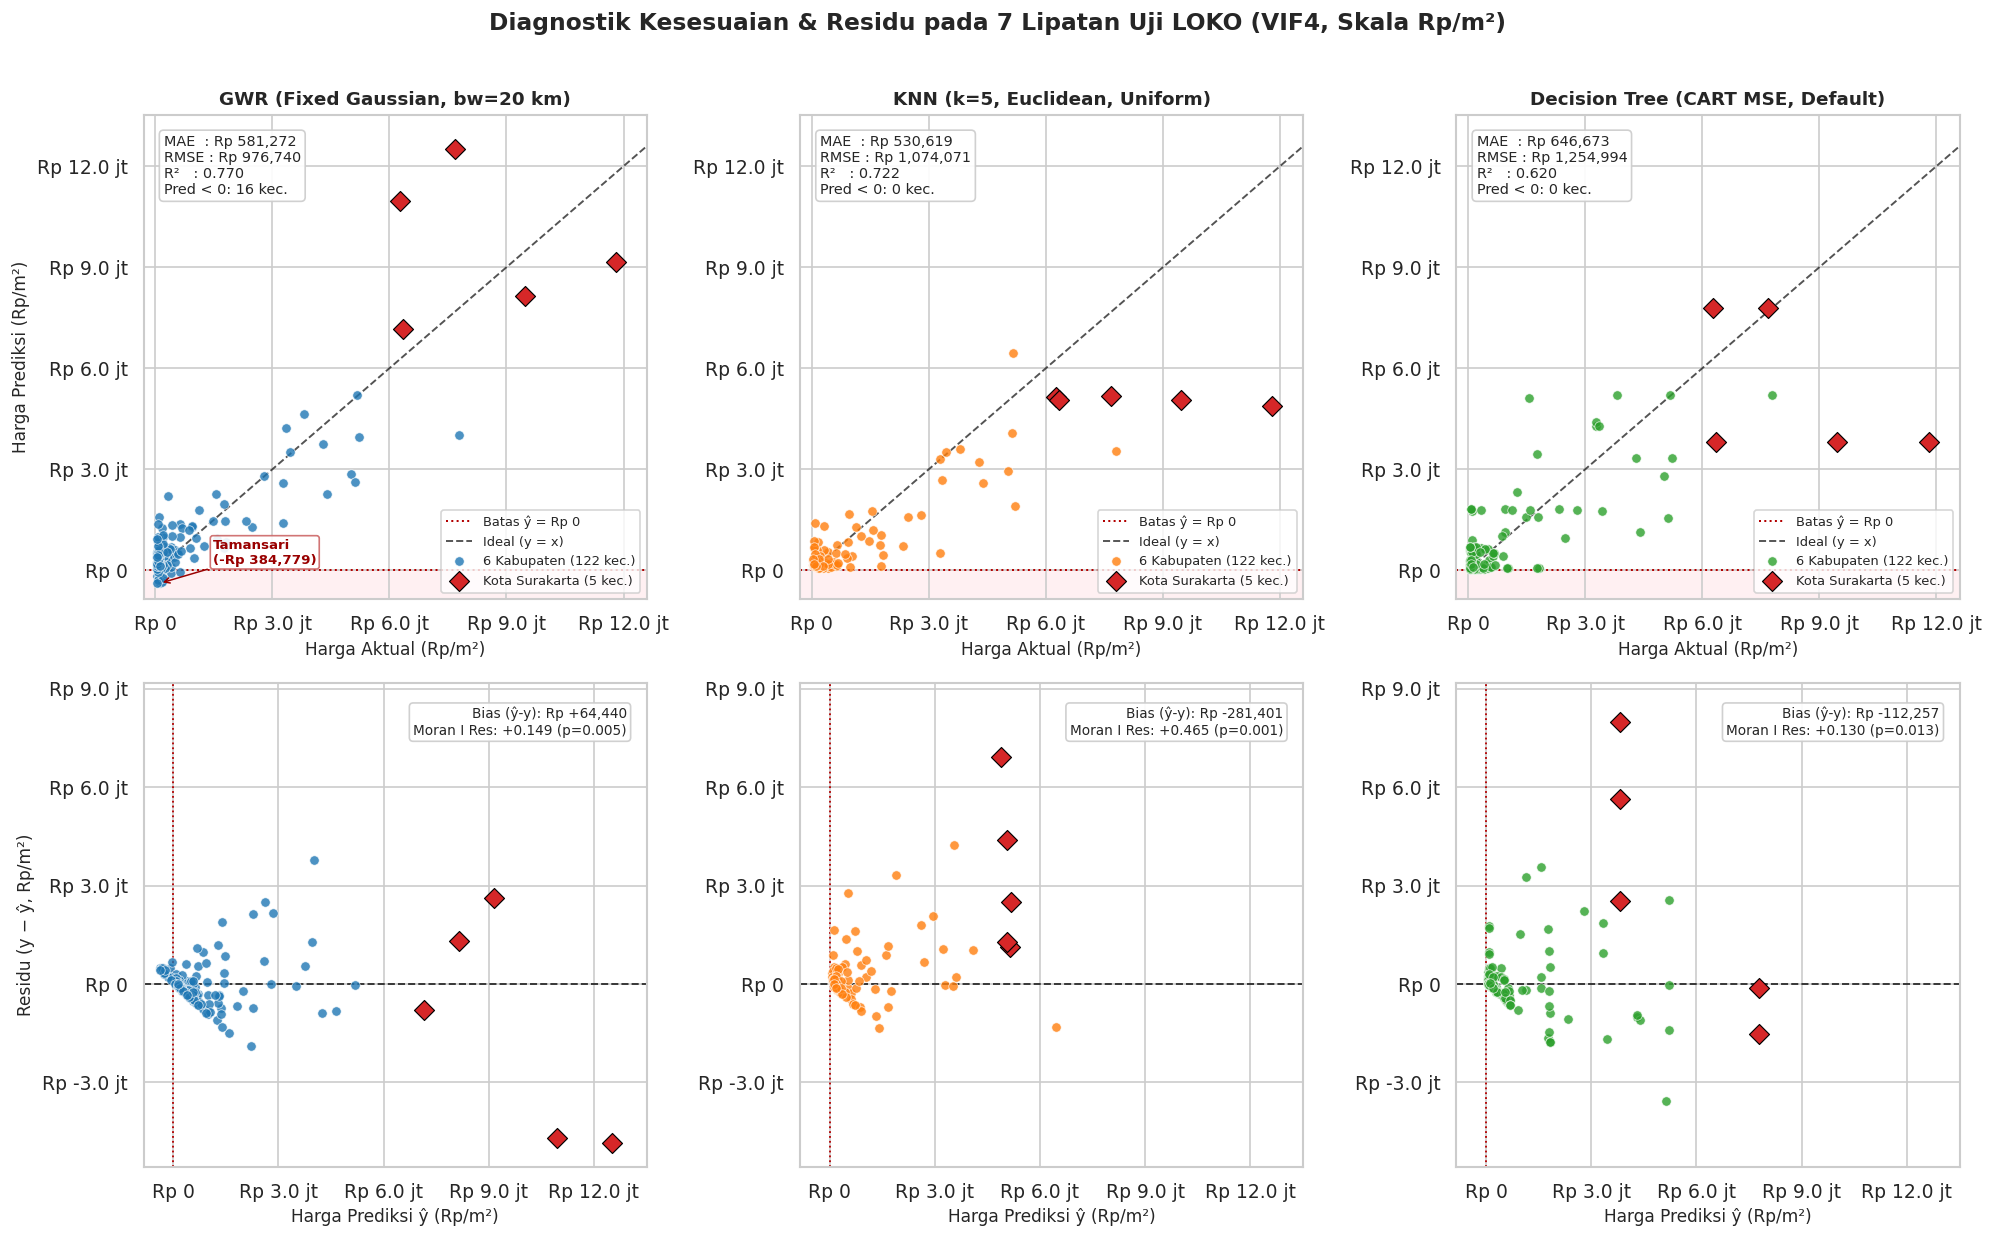

Tersimpan: figures/presentasi_3_model/05_aktual_vs_prediksi_3_model.png


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16.8, 10.2), sharex=False)

min_pred_all = float(pred_table[["pred_GWR", "pred_KNN", "pred_Decision Tree"]].min().min())
max_pred_all = float(max(pred_table[TARGET_COL].max(), pred_table[["pred_GWR", "pred_KNN", "pred_Decision Tree"]].max().max()))
y_low = min(-850_000.0, min_pred_all * 1.35)
y_high = max_pred_all * 1.08
x_low, x_high = -300_000.0, 12_600_000.0

is_solo = pred_table["kab_kota"] == "Kota Surakarta"

# Baris Atas: Harga Aktual vs Prediksi
for col_i, (label_full, short_key, _, _) in enumerate(MODEL_SPECS):
    ax = axes[0, col_i]
    y_pred = pred_table[f"pred_{short_key}"].to_numpy()
    y_act = pred_table[TARGET_COL].to_numpy()

    ax.axhspan(y_low, 0.0, color="#ffebee", alpha=0.75, zorder=0)
    ax.axhline(0.0, color="#b30000", linestyle=":", linewidth=1.2, zorder=1, label="Batas ŷ = Rp 0")
    ax.plot([0.0, y_high], [0.0, y_high], "k--", linewidth=1.15, alpha=0.75, zorder=1, label="Ideal (y = x)")

    ax.scatter(y_act[~is_solo], y_pred[~is_solo], s=32, alpha=0.80, color=MODEL_COLORS[short_key], edgecolors="white", linewidths=0.45, zorder=3, label="6 Kabupaten (122 kec.)")
    ax.scatter(y_act[is_solo], y_pred[is_solo], s=72, marker="D", color="#d62728", edgecolors="black", linewidths=0.7, zorder=4, label="Kota Surakarta (5 kec.)")

    row_m = df_summary[df_summary["Key"] == short_key].iloc[0]
    ax.text(
        0.04, 0.96,
        f"MAE  : Rp {row_m['MAE (Rp/m²)']:,.0f}\nRMSE : Rp {row_m['RMSE (Rp/m²)']:,.0f}\nR²   : {row_m['R²']:.3f}\nPred < 0: {int(row_m['Prediksi < 0'])} kec.",
        transform=ax.transAxes, va="top", ha="left", fontsize=8.6,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#cccccc", alpha=0.92),
    )

    if short_key == "GWR":
        worst_neg = pred_table.sort_values("pred_GWR").iloc[0]
        ax.annotate(
            f"{worst_neg['kecamatan']}\n(-Rp {abs(worst_neg['pred_GWR']):,.0f})",
            xy=(worst_neg[TARGET_COL], worst_neg["pred_GWR"]),
            xytext=(32, 12), textcoords="offset points",
            fontsize=8.0, fontweight="bold", color="#990000",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#cc6666", alpha=0.9),
            arrowprops=dict(arrowstyle="->", color="#990000", lw=0.9),
        )

    ax.set_title(label_full, fontsize=11.0)
    ax.set_xlabel("Harga Aktual (Rp/m²)")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(3_000_000))
    ax.yaxis.set_major_locator(mticker.MultipleLocator(3_000_000))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
    ax.set_xlim(x_low, x_high)
    ax.set_ylim(y_low, y_high)
    ax.legend(loc="lower right", fontsize=7.8, frameon=True)

axes[0, 0].set_ylabel("Harga Prediksi (Rp/m²)")

# Baris Bawah: Residu (y - y_hat) vs Prediksi (y_hat) gaya PredictionErrorDisplay
res_all = np.concatenate([pred_table[f"res_{k}"].to_numpy() for _, k, _, _ in MODEL_SPECS])
res_low = min(-3_500_000.0, float(res_all.min()) * 1.15)
res_high = max(8_500_000.0, float(res_all.max()) * 1.15)

for col_i, (label_full, short_key, _, _) in enumerate(MODEL_SPECS):
    ax = axes[1, col_i]
    y_pred = pred_table[f"pred_{short_key}"].to_numpy()
    res_val = pred_table[f"res_{short_key}"].to_numpy()

    ax.axhline(0.0, color="black", linestyle="--", linewidth=1.15, alpha=0.75, zorder=1)
    ax.axvline(0.0, color="#b30000", linestyle=":", linewidth=1.1, zorder=1)
    ax.scatter(y_pred[~is_solo], res_val[~is_solo], s=32, alpha=0.80, color=MODEL_COLORS[short_key], edgecolors="white", linewidths=0.45, zorder=3, label="6 Kabupaten")
    ax.scatter(y_pred[is_solo], res_val[is_solo], s=72, marker="D", color="#d62728", edgecolors="black", linewidths=0.7, zorder=4, label="Kota Surakarta")

    row_m = df_summary[df_summary["Key"] == short_key].iloc[0]
    ax.text(
        0.96, 0.95,
        f"Bias (ŷ-y): Rp {row_m['Bias / ME (Rp/m²)']:+,.0f}\nMoran I Res: {row_m['Moran I Residu']:+.3f} (p={row_m['p_sim Moran']:.3f})",
        transform=ax.transAxes, va="top", ha="right", fontsize=8.2,
        bbox=dict(boxstyle="round,pad=0.28", fc="white", ec="#cccccc", alpha=0.92),
    )
    ax.set_xlabel("Harga Prediksi ŷ (Rp/m²)")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(3_000_000))
    ax.yaxis.set_major_locator(mticker.MultipleLocator(3_000_000))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
    ax.set_xlim(y_low, y_high)
    ax.set_ylim(res_low, res_high)

axes[1, 0].set_ylabel("Residu (y − ŷ, Rp/m²)")
fig.suptitle("Diagnostik Kesesuaian & Residu pada 7 Lipatan Uji LOKO (VIF4, Skala Rp/m²)", fontsize=14.0, fontweight="bold", y=1.01)
fig.tight_layout()
out5 = FIG_DIR / "05_aktual_vs_prediksi_3_model.png"
fig.savefig(out5, dpi=220, bbox_inches="tight")
plt.show()
print("Tersimpan:", out5.relative_to(ROOT))

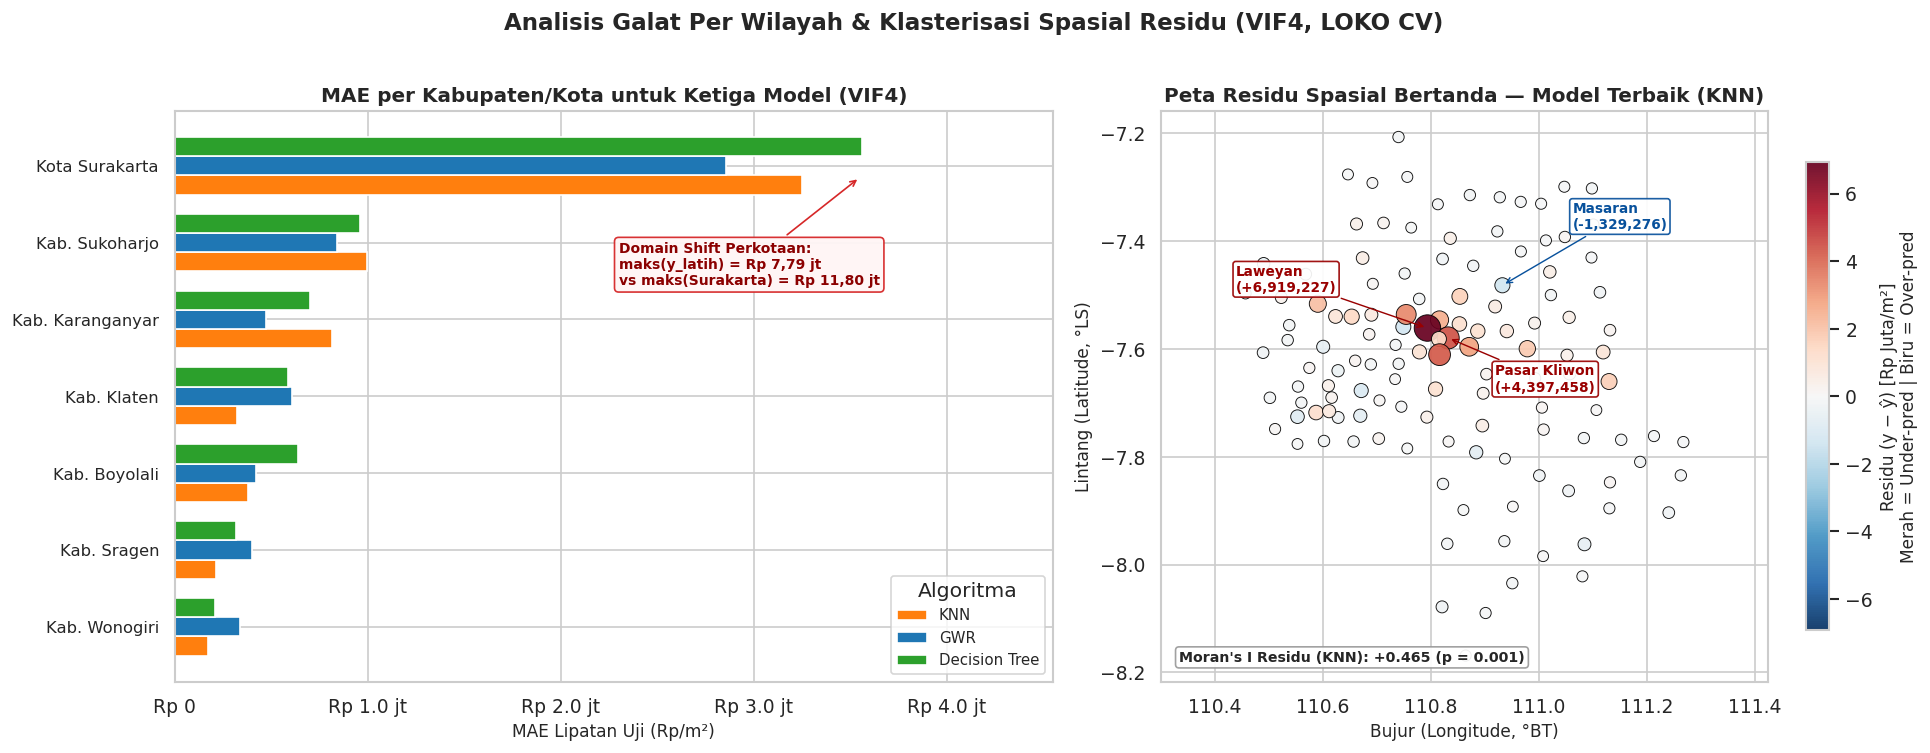

Tersimpan: figures/presentasi_3_model/06_analisis_galat_per_wilayah.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16.4, 6.2), gridspec_kw={"width_ratios": [1.18, 1.02]})

# Panel kiri: MAE per kabupaten/kota dengan sumbu x hingga Rp 4.0 jt
ax = axes[0]
order_reg = pivot_mae.mean(axis=1).sort_values(ascending=True).index.tolist()
y_pos = np.arange(len(order_reg))
bar_h = 0.25

for offset, model_k in zip([-bar_h, 0.0, bar_h], ["KNN", "GWR", "Decision Tree"]):
    vals = [pivot_mae.loc[r, model_k] for r in order_reg]
    ax.barh(y_pos + offset, vals, height=bar_h, color=MODEL_COLORS[model_k], edgecolor="white", label=model_k)

ax.set_yticks(y_pos)
ax.set_yticklabels([r.replace("Kabupaten ", "Kab. ") for r in order_reg], fontsize=9.8)
ax.set_xlim(0, 4_550_000)
ax.xaxis.set_major_locator(mticker.MultipleLocator(1_000_000))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
ax.set_xlabel("MAE Lipatan Uji (Rp/m²)")
ax.set_title("MAE per Kabupaten/Kota untuk Ketiga Model (VIF4)")
ax.legend(title="Algoritma", loc="lower right", frameon=True, fontsize=9.0)

solo_idx = order_reg.index("Kota Surakarta")
ax.annotate(
    "Domain Shift Perkotaan:\nmaks(y_latih) = Rp 7,79 jt\nvs maks(Surakarta) = Rp 11,80 jt",
    xy=(3_550_000, solo_idx - 0.15),
    xytext=(2_300_000, solo_idx - 1.55),
    fontsize=8.3, color="#8b0000", fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="#fff5f5", ec="#d62728", alpha=0.95),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.0),
)

# Panel kanan: Peta Spasial Residu Bertanda (y - y_hat) untuk Model MAE Terbaik (KNN)
best_key = df_summary.iloc[0]["Key"]
best_row = df_summary.iloc[0]
res_col = f"res_{best_key}"
res_m = pred_table[res_col] / 1_000_000.0
v_abs = float(max(abs(res_m.min()), abs(res_m.max())))
norm_div = TwoSlopeNorm(vmin=-v_abs, vcenter=0.0, vmax=v_abs)

ax = axes[1]
sc = ax.scatter(
    pred_table["lon"],
    pred_table["lat"],
    c=res_m,
    s=42 + 210 * (np.abs(res_m) / v_abs),
    cmap="RdBu_r",
    norm=norm_div,
    edgecolors="black",
    linewidths=0.55,
    alpha=0.92,
)
cbar = fig.colorbar(sc, ax=ax, shrink=0.82)
cbar.set_label("Residu (y − ŷ) [Rp Juta/m²]\nMerah = Under-pred | Biru = Over-pred")

# Sorot 2 under-prediction terbesar & 1 over-prediction terbesar tanpa tumpang tindih
top_under = pred_table.sort_values(res_col, ascending=False).head(2)
top_over = pred_table.sort_values(res_col, ascending=True).head(1)
callouts = [
    (top_under.iloc[0], (-115, 22), "#990000"),
    (top_under.iloc[1], (28, -32), "#990000"),
    (top_over.iloc[0], (42, 34), "#08519c"),
]
for r_item, (dx, dy), clr in callouts:
    rv = r_item[res_col]
    ax.annotate(
        f"{r_item['kecamatan']}\n({rv:+,.0f})",
        xy=(r_item["lon"], r_item["lat"]),
        xytext=(dx, dy), textcoords="offset points",
        fontsize=8.2, fontweight="bold", color=clr,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=clr, alpha=0.92),
        arrowprops=dict(arrowstyle="->", color=clr, lw=0.85),
    )

ax.text(
    0.03, 0.03,
    f"Moran's I Residu ({best_key}): {best_row['Moran I Residu']:+.3f} (p = {best_row['p_sim Moran']:.3f})",
    transform=ax.transAxes, ha="left", va="bottom", fontsize=8.5, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#999999", alpha=0.92),
)
ax.set_title(f"Peta Residu Spasial Bertanda — Model Terbaik ({best_key})")
ax.set_xlabel("Bujur (Longitude, °BT)")
ax.set_ylabel("Lintang (Latitude, °LS)")
ax.set_aspect("equal", adjustable="datalim")

fig.suptitle("Analisis Galat Per Wilayah & Klasterisasi Spasial Residu (VIF4, LOKO CV)", fontsize=13.8, fontweight="bold", y=1.01)
fig.tight_layout()
out6 = FIG_DIR / "06_analisis_galat_per_wilayah.png"
fig.savefig(out6, dpi=220, bbox_inches="tight")
plt.show()
print("Tersimpan:", out6.relative_to(ROOT))

## 7. Tiga Uji Diagnostik Pemodelan (Tanpa *Tuning*, Dalam Batas R2)

Untuk membuktikan secara empiris mengapa keputusan prapemrosesan dan validasi pada Bagian 5 dipilih (serta meluruskan rasionalisasi draf lama), dijalankan tiga perbandingan diagnostik terkontrol pada ketiga algoritma default yang sama:

- **Diagnostik A — Efek Multikolinearitas (`ALL7` vs `VIF4`)**: Mengukur dampak langsung pengurangan VIF (`36,65 -> 2,05`) terhadap stabilitas matriks lokal GWR (`cond(X_w)`), prediksi negatif, dan akurasi KNN/CART.
- **Diagnostik B — Target $\ln(y)$ + *Smearing* Duan (1983) Terisolasi Lipatan vs $\exp(\hat{z})$ Naif**: Dalam ekonometrika, mengembalikan prediksi log via $\exp(\hat{z})$ saja menimbulkan bias ke bawah akibat ketaksamaan Jensen; faktor *smearing* Duan (1983) $\hat{\phi} = \frac{1}{n_{\text{tr}}}\sum \exp(z_{\text{tr}} - \hat{z}_{\text{tr}})$ (dihitung **hanya pada data latih lipatan**) memulihkan nilai harapan linear. Uji ini membuktikan dua hal penting: (1) *Duan smearing* secara dramatis memperbaiki **KNN** (`MAE 487 rb`, `R² = 0,807`), tetapi (2) **GWR pada $\ln(y)$ tetap meledak** di Kota Surakarta (`MAE Rp 29,6 jt/m²`, maks `Rp 2,65 miliar/m²`) bahkan pada `VIF4`, yang membuktikan penyebab utamanya adalah **ekstrapolasi eksponensial di luar selubung fitur ($z = +7{,}1$)** — bukan semata-mata multikolinearitas.
- **Diagnostik C — Validasi Spasial LOKO 7-Fold vs Random 7-Fold CV & Sub-Analisis 6 Kabupaten Non-Surakarta (`n=122`)**: Mengukur *optimism bias* akibat kebocoran autokorelasi spasial pada Random CV (Roberts et al., 2017; Ploton et al., 2020) sekaligus mengisolasi performa murni pada 6 kabupaten penyangga tanpa *domain shift* Kota Surakarta.

=== DIAGNOSTIK A: EFEK MULTIKOLINEARITAS (ALL7 vs VIF4) ===
GWR maks cond(X_w): ALL7 = 32.32 (23/127 > 30) -> VIF4 = 4.38 (0/127 > 30)


,Model,MAE ALL7,MAE VIF4,RMSE ALL7,RMSE VIF4,R² ALL7,R² VIF4,Neg ALL7,Neg VIF4
0,GWR,"571,672","581,272","1,124,453","976,740",0.6950,0.7699,22,16
1,KNN,"577,713","530,619","1,187,973","1,074,071",0.6596,0.7218,0,0
2,Decision Tree,"588,711","646,673","1,155,344","1,254,994",0.6781,0.6201,0,0



=== DIAGNOSTIK B: TARGET ln(y) + DUAN (1983) SMEARING vs EXP() NAIF (VIF4) ===


,Model,Skema Target,MAE (Rp/m²),RMSE (Rp/m²),R²,Bias (Rp/m²),Maks Prediksi
0,GWR,Linear Rp/m²,"581,272","976,740",0.7699,"+64,440","12,515,811"
1,GWR,ln(y) + exp() Naif,"22,999,699","190,588,059",-8759.9382,"+22,074,281","2,051,876,442"
2,GWR,ln(y) + Duan (1983),"29,595,761","246,313,036",-14632.0224,"+28,853,061","2,649,064,097"
3,KNN,Linear Rp/m²,"530,619","1,074,071",0.7218,"-281,401","6,465,678"
4,KNN,ln(y) + exp() Naif,"566,354","1,179,774",0.6643,"-437,200","5,224,500"
5,KNN,ln(y) + Duan (1983),"487,126","894,391",0.8071,"-114,835","7,778,623"
6,Decision Tree,Linear Rp/m²,"646,673","1,254,994",0.6201,"-112,257","7,789,431"
7,Decision Tree,ln(y) + exp() Naif,"696,675","1,279,425",0.6052,"-93,947","7,789,431"
8,Decision Tree,ln(y) + Duan (1983),"696,675","1,279,425",0.6052,"-93,947","7,789,431"



=== DIAGNOSTIK C: LOKO 7-FOLD vs RANDOM 7-FOLD CV vs 6-KAB NON-SURAKARTA (VIF4 LINEAR) ===


,Model,Skema Validasi,MAE (Rp/m²),MdAE (Rp/m²),RMSE (Rp/m²),R²
0,GWR,LOKO 7-Fold (127 kec.),"581,272","347,595","976,740",0.7699
1,GWR,Random 7-Fold (127 kec.),"482,991","251,675","866,738",0.8188
2,GWR,LOKO Non-Surakarta (122 kec.),"488,093","338,971","738,380",0.7169
3,KNN,LOKO 7-Fold (127 kec.),"530,619","193,639","1,074,071",0.7218
4,KNN,Random 7-Fold (127 kec.),"520,034","200,207","1,036,251",0.7410
5,KNN,LOKO Non-Surakarta (122 kec.),"419,248","168,055","757,810",0.7018
6,Decision Tree,LOKO 7-Fold (127 kec.),"646,673","242,426","1,254,994",0.6201
7,Decision Tree,Random 7-Fold (127 kec.),"638,252","239,089","1,288,032",0.5999
8,Decision Tree,LOKO Non-Surakarta (122 kec.),"527,176","239,317","884,621",0.5937


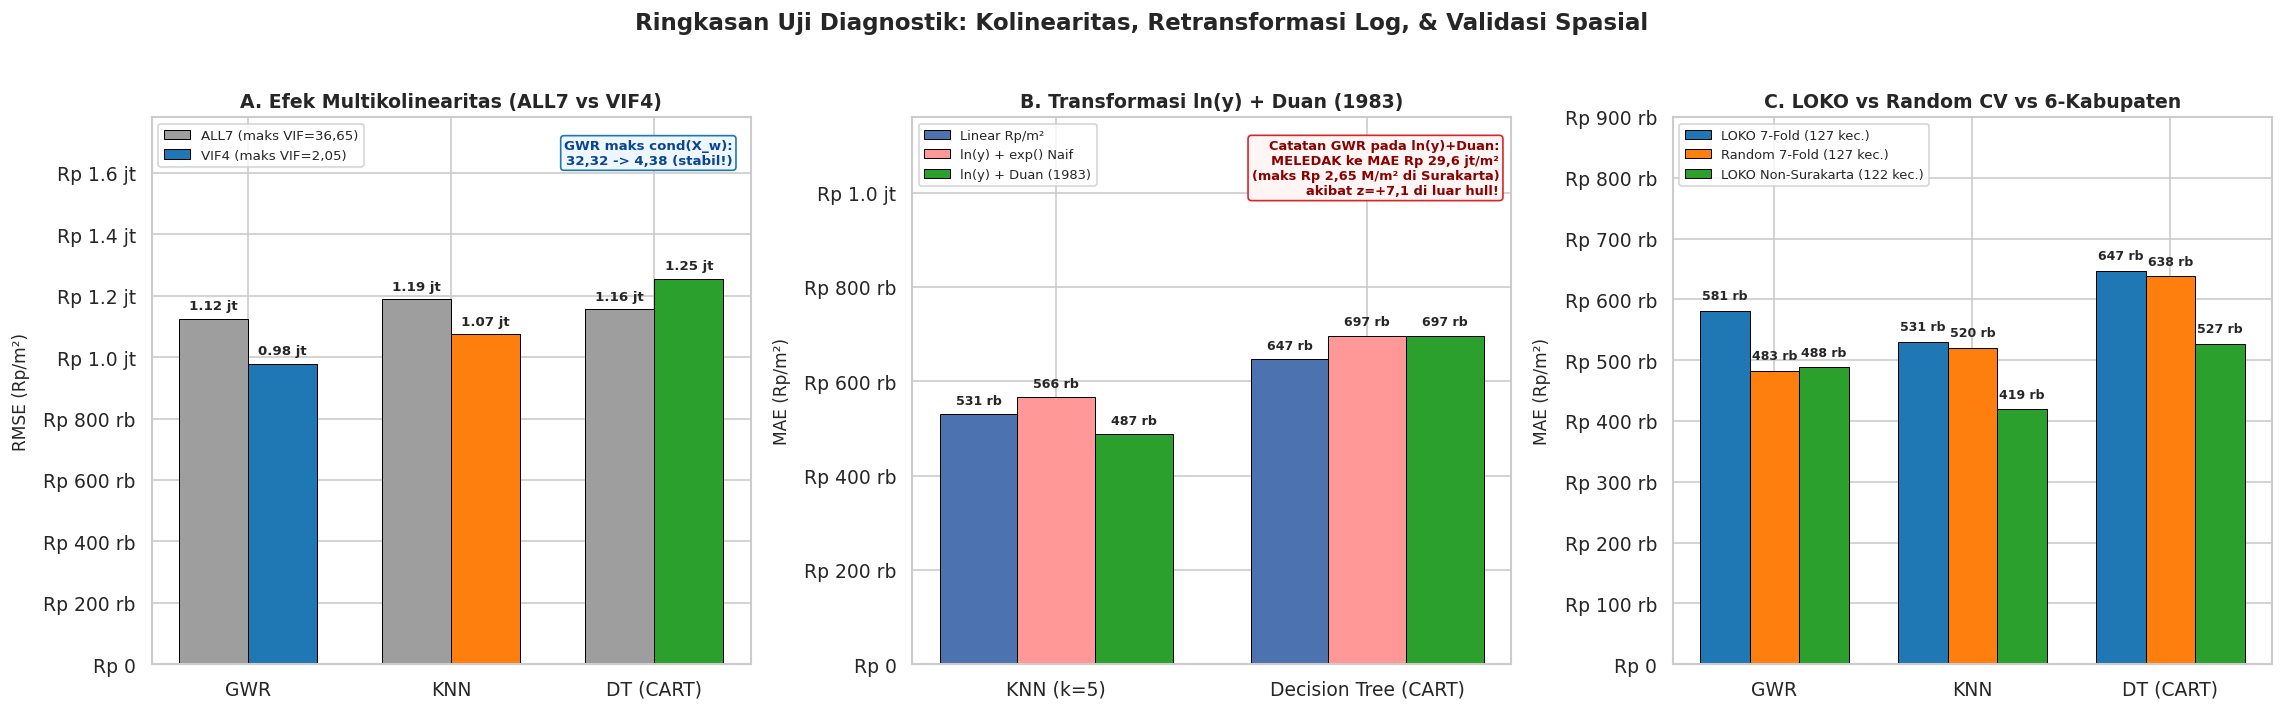

Tersimpan: figures/presentasi_3_model/07_diagnostik_validasi_dan_transformasi.png


In [12]:
# --- DIAGNOSTIK A: ALL7 vs VIF4 (Linear Rp/m²) ---
oof_all7, _, gwr_diag_all7, _ = run_loko_experiment(ALL7_FEATURES, log_target=False, use_duan=False)

# --- DIAGNOSTIK B: ln(y) + Naif exp() vs ln(y) + Duan (1983) Smearing (pada VIF4) ---
oof_lny_naif, _, _, _ = run_loko_experiment(VIF4_FEATURES, log_target=True, use_duan=False)
oof_lny_duan, _, _, _ = run_loko_experiment(VIF4_FEATURES, log_target=True, use_duan=True)

# --- DIAGNOSTIK C1: Random 7-Fold CV (seed=42, pada VIF4 Linear) ---
rng_cv = np.random.default_rng(42)
perm_idx = rng_cv.permutation(len(df))
rand_folds = np.array_split(perm_idx, 7)
X_vif4 = df[VIF4_FEATURES].to_numpy(dtype=float)
oof_random = {k: np.full(len(df), np.nan, dtype=float) for _, k, _, _ in MODEL_SPECS}

for te_idx in rand_folds:
    te_mask = np.zeros(len(df), dtype=bool)
    te_mask[te_idx] = True
    tr_mask = ~te_mask
    mu_r, sd_r = fit_standardizer(X_vif4[tr_mask])
    X_tr_r = apply_standardizer(X_vif4[tr_mask], mu_r, sd_r)
    X_te_r = apply_standardizer(X_vif4[te_mask], mu_r, sd_r)
    for _, short_key, builder, needs_coords in MODEL_SPECS:
        m = builder()
        if needs_coords:
            m.fit(X_tr_r, y_all[tr_mask], coords_all[tr_mask])
            yh = m.predict(X_te_r, coords_all[te_mask])
        else:
            m.fit(X_tr_r, y_all[tr_mask])
            yh = m.predict(X_te_r)
        assert np.isfinite(yh).all()
        oof_random[short_key][te_mask] = yh

for k in oof_random:
    assert not np.isnan(oof_random[k]).any()

# Susun tabel perbandingan Diagnostik A, B, C
diag_a_rows = []
for sk in ["GWR", "KNN", "Decision Tree"]:
    m7 = evaluate_predictions_scratch(y_all, oof_all7[sk])
    m4 = evaluate_predictions_scratch(y_all, oof_vif4[sk])
    diag_a_rows.append({
        "Model": sk,
        "MAE ALL7": m7["MAE (Rp/m²)"], "MAE VIF4": m4["MAE (Rp/m²)"],
        "RMSE ALL7": m7["RMSE (Rp/m²)"], "RMSE VIF4": m4["RMSE (Rp/m²)"],
        "R² ALL7": m7["R²"], "R² VIF4": m4["R²"],
        "Neg ALL7": m7["Prediksi < 0"], "Neg VIF4": m4["Prediksi < 0"],
    })
df_diag_a = pd.DataFrame(diag_a_rows)
print("=== DIAGNOSTIK A: EFEK MULTIKOLINEARITAS (ALL7 vs VIF4) ===")
print(
    f"GWR maks cond(X_w): ALL7 = {gwr_diag_all7['cond_xw'].max():.2f} ({int((gwr_diag_all7['cond_xw']>30).sum())}/127 > 30) "

    f"-> VIF4 = {gwr_diag_vif4['cond_xw'].max():.2f} ({int((gwr_diag_vif4['cond_xw']>30).sum())}/127 > 30)"
)
display(df_diag_a.style.format({"MAE ALL7": "{:,.0f}", "MAE VIF4": "{:,.0f}", "RMSE ALL7": "{:,.0f}", "RMSE VIF4": "{:,.0f}", "R² ALL7": "{:.4f}", "R² VIF4": "{:.4f}"}))

diag_b_rows = []
for sk in ["GWR", "KNN", "Decision Tree"]:
    for skema, pred_arr in [("Linear Rp/m²", oof_vif4[sk]), ("ln(y) + exp() Naif", oof_lny_naif[sk]), ("ln(y) + Duan (1983)", oof_lny_duan[sk])]:
        mt = evaluate_predictions_scratch(y_all, pred_arr)
        diag_b_rows.append({
            "Model": sk, "Skema Target": skema,
            "MAE (Rp/m²)": mt["MAE (Rp/m²)"], "RMSE (Rp/m²)": mt["RMSE (Rp/m²)"],
            "R²": mt["R²"], "Bias (Rp/m²)": mt["Bias / ME (Rp/m²)"], "Maks Prediksi": float(np.max(pred_arr)),
        })
df_diag_b = pd.DataFrame(diag_b_rows)
print("\n=== DIAGNOSTIK B: TARGET ln(y) + DUAN (1983) SMEARING vs EXP() NAIF (VIF4) ===")
display(df_diag_b.style.format({"MAE (Rp/m²)": "{:,.0f}", "RMSE (Rp/m²)": "{:,.0f}", "R²": "{:.4f}", "Bias (Rp/m²)": "{:+,.0f}", "Maks Prediksi": "{:,.0f}"}))

non_solo_mask = groups != "Kota Surakarta"
diag_c_rows = []
for sk in ["GWR", "KNN", "Decision Tree"]:
    m_loko = evaluate_predictions_scratch(y_all, oof_vif4[sk])
    m_rand = evaluate_predictions_scratch(y_all, oof_random[sk])
    m_ns = evaluate_predictions_scratch(y_all[non_solo_mask], oof_vif4[sk][non_solo_mask], coords_sub=coords_all[non_solo_mask])
    for skema, mt in [("LOKO 7-Fold (127 kec.)", m_loko), ("Random 7-Fold (127 kec.)", m_rand), ("LOKO Non-Surakarta (122 kec.)", m_ns)]:
        diag_c_rows.append({
            "Model": sk, "Skema Validasi": skema,
            "MAE (Rp/m²)": mt["MAE (Rp/m²)"], "MdAE (Rp/m²)": mt["MdAE (Rp/m²)"],
            "RMSE (Rp/m²)": mt["RMSE (Rp/m²)"], "R²": mt["R²"],
        })
df_diag_c = pd.DataFrame(diag_c_rows)
print("\n=== DIAGNOSTIK C: LOKO 7-FOLD vs RANDOM 7-FOLD CV vs 6-KAB NON-SURAKARTA (VIF4 LINEAR) ===")
display(df_diag_c.style.format({"MAE (Rp/m²)": "{:,.0f}", "MdAE (Rp/m²)": "{:,.0f}", "RMSE (Rp/m²)": "{:,.0f}", "R²": "{:.4f}"}))

# ==============================================================================
# FIGUR 07: RINGKASAN VISUAL DIAGNOSTIK A, B, & C
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(19.2, 5.8))
models_ord = ["GWR", "KNN", "Decision Tree"]
x_m = np.arange(len(models_ord))
w_b = 0.34

# Panel A: ALL7 vs VIF4 (RMSE)
rmse_7 = [df_diag_a.set_index("Model").loc[m, "RMSE ALL7"] for m in models_ord]
rmse_4 = [df_diag_a.set_index("Model").loc[m, "RMSE VIF4"] for m in models_ord]
b1 = axes[0].bar(x_m - w_b/2, rmse_7, width=w_b, color="#9e9e9e", edgecolor="black", lw=0.6, label="ALL7 (maks VIF=36,65)")
b2 = axes[0].bar(x_m + w_b/2, rmse_4, width=w_b, color=[MODEL_COLORS[m] for m in models_ord], edgecolor="black", lw=0.6, label="VIF4 (maks VIF=2,05)")
axes[0].set_xticks(x_m)
axes[0].set_xticklabels([m.replace("Decision Tree", "DT (CART)") for m in models_ord])
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
axes[0].set_ylim(0, max(rmse_7 + rmse_4) * 1.42)
axes[0].set_ylabel("RMSE (Rp/m²)", labelpad=8)
axes[0].set_title("A. Efek Multikolinearitas (ALL7 vs VIF4)", fontsize=11.3)
axes[0].legend(loc="upper left", fontsize=8.0, frameon=True)
for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 22_000, f"{h/1e6:.2f} jt", ha="center", va="bottom", fontsize=8.0, fontweight="bold")
axes[0].text(0.97, 0.96, "GWR maks cond(X_w):\n32,32 -> 4,38 (stabil!)", transform=axes[0].transAxes, ha="right", va="top", fontsize=8.0, fontweight="bold", color="#084594", bbox=dict(boxstyle="round,pad=0.25", fc="#eef6ff", ec="#1f77b4"))

# Panel B: Target Linear vs ln(y)+Naif vs ln(y)+Duan (KNN & DT bars + GWR blowup callout)
sub_b_models = ["KNN", "Decision Tree"]
xb = np.arange(len(sub_b_models))
wb3 = 0.25
skemas = [("Linear Rp/m²", "#4c72b0"), ("ln(y) + exp() Naif", "#ff9896"), ("ln(y) + Duan (1983)", "#2ca02c")]
piv_b = df_diag_b.pivot(index="Model", columns="Skema Target", values="MAE (Rp/m²)")
for idx_s, (sk_name, clr_s) in enumerate(skemas):
    vals_s = [piv_b.loc[m, sk_name] for m in sub_b_models]
    bars_s = axes[1].bar(xb + (idx_s - 1)*wb3, vals_s, width=wb3, color=clr_s, edgecolor="black", lw=0.6, label=sk_name)
    for br in bars_s:
        h = br.get_height()
        axes[1].text(br.get_x() + br.get_width()/2, h + 15_000, f"{h/1000:,.0f} rb", ha="center", va="bottom", fontsize=7.6, fontweight="bold")
axes[1].set_xticks(xb)
axes[1].set_xticklabels(["KNN (k=5)", "Decision Tree (CART)"])
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
axes[1].set_ylim(0, 1_160_000)
axes[1].set_ylabel("MAE (Rp/m²)", labelpad=8)
axes[1].set_title("B. Transformasi ln(y) + Duan (1983)", fontsize=11.3)
axes[1].legend(loc="upper left", fontsize=7.8, frameon=True)
axes[1].text(
    0.98, 0.96,
    "Catatan GWR pada ln(y)+Duan:\nMELEDAK ke MAE Rp 29,6 jt/m²\n(maks Rp 2,65 M/m² di Surakarta)\nakibat z=+7,1 di luar hull!",
    transform=axes[1].transAxes, ha="right", va="top", fontsize=7.8, fontweight="bold", color="#8b0000",
    bbox=dict(boxstyle="round,pad=0.28", fc="#fff5f5", ec="#d62728"),
)

# Panel C: LOKO vs Random CV vs 6-Kabupaten Non-Surakarta
piv_c = df_diag_c.pivot(index="Model", columns="Skema Validasi", values="MAE (Rp/m²)")
skemas_c = [("LOKO 7-Fold (127 kec.)", "#1f77b4"), ("Random 7-Fold (127 kec.)", "#ff7f0e"), ("LOKO Non-Surakarta (122 kec.)", "#2ca02c")]
for idx_c, (sk_name, clr_c) in enumerate(skemas_c):
    vals_c = [piv_c.loc[m, sk_name] for m in models_ord]
    bars_c = axes[2].bar(x_m + (idx_c - 1)*wb3, vals_c, width=wb3, color=clr_c, edgecolor="black", lw=0.6, label=sk_name)
    for br in bars_c:
        h = br.get_height()
        axes[2].text(br.get_x() + br.get_width()/2, h + 14_000, f"{h/1000:,.0f} rb", ha="center", va="bottom", fontsize=7.5, fontweight="bold")
axes[2].set_xticks(x_m)
axes[2].set_xticklabels([m.replace("Decision Tree", "DT (CART)") for m in models_ord])
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rupiah_axis))
axes[2].set_ylim(0, 900_000)
axes[2].set_ylabel("MAE (Rp/m²)", labelpad=8)
axes[2].set_title("C. LOKO vs Random CV vs 6-Kabupaten", fontsize=11.3)
axes[2].legend(loc="upper left", fontsize=7.8, frameon=True)

fig.suptitle("Ringkasan Uji Diagnostik: Kolinearitas, Retransformasi Log, & Validasi Spasial", fontsize=13.8, fontweight="bold", y=1.02)
fig.tight_layout()
out7 = FIG_DIR / "07_diagnostik_validasi_dan_transformasi.png"
fig.savefig(out7, dpi=220, bbox_inches="tight")
plt.show()
print("Tersimpan:", out7.relative_to(ROOT))

## 8. Kesimpulan, Batasan Interpretasi, & Daftar Pustaka Terverifikasi

### Poin Kunci Presentasi
1. **Integritas Data & Spasial**: Dataset bersih `127 × 18` bebas nilai hilang dan seluruh `127/127` titik koordinat BIG KSP Satu Peta terverifikasi berada di dalam poligon administrasi resmi.
2. **Kurasi Kolinearitas (`ALL7 -> VIF4`) Tanpa Kebocoran**: Menghapus fitur komposisional dan duplikasi densitas–jumlah memangkas maks VIF dari `36,65` menjadi `2,05`, menstabilkan kondisi matriks lokal GWR (`cond(X_w)` turun dari `32,32` menjadi `4,38`), menurunkan RMSE GWR sebesar **-13,1%** (`1,12 jt -> 0,98 jt`), dan menurunkan MAE KNN sebesar **-8,2%** (`578 rb -> 531 rb`).
3. **Perbandingan Adil 3 Model Default (`VIF4`, Linear `Rp/m²`, LOKO CV)**:
   - **KNN (`k=5, uniform`)** mencatat MAE terendah (`Rp 530.619/m²`), MdAE terbaik (`Rp 193.639/m²`), WAPE terendah (`47,6%`), RMSLE terbaik (`1,067`), dan **0 prediksi negatif** — tetapi residunya masih memiliki autokorelasi spasial terkuat (`Moran's I = +0,465, p = 0,001`).
   - **GWR (`Fixed Gaussian bw=20 km`, intersep bebas penalti)** mencapai RMSE (`Rp 976.740/m²`) dan $R^2$ (`0,770`) tertinggi dengan autokorelasi residu rendah (`I = +0,149`), **namun** menghasilkan **`16/127` prediksi negatif tidak fisik** (hingga `-Rp 384.779/m²` di pedesaan Wonogiri) karena ekstrapolasi linear dan penyusutan bobot lokal (`sum(w) = 0,949` pada jarak `44,25 km`).
   - **Decision Tree (`CART MSE, default`)** mencatat galat tertinggi (`MAE Rp 646.673/m²`, `R² = 0,620`) karena menghafal data latih hingga daun murni (`n_leaves == n_train`, kedalaman `13–16`).
4. **Transformasi $\ln(y)$ & *Domain Shift* Perkotaan**: *Smearing* Duan (1983) terisolasi lipatan meningkatkan akurasi KNN menjadi `MAE Rp 487.126/m²` (`R² = 0,807`), tetapi GWR pada $\ln(y)$ meledak di Kota Surakarta (`Rp 2,65 miliar/m²`) akibat ekstrapolasi eksponensial di luar selubung latih (`z_mean = +7,10`).
5. **Batasan (*Ecological Fallacy* & Cakupan)**: Seluruh angka mencerminkan **harga rata-rata tingkat kecamatan tahun 2020** (`n = 127`), bukan harga transaksi persil tanah individual ataupun kondisi tahun berjalan.

### Landasan Metodologi & Daftar Pustaka Internet Terverifikasi
| Topik | Referensi Akademik / Dokumentasi Resmi | Tautan Terverifikasi |
|---|---|---|
| Validasi Blok Spasial & Kebocoran Autokorelasi | Roberts et al. (2017), *Ecography* 40(8): 913–929 | https://doi.org/10.1111/ecog.02881 |
| Inflasi Performa Random CV vs Spasial CV | Ploton et al. (2020), *Nature Communications* 11: 4540 | https://www.nature.com/articles/s41467-020-18321-y |
| Kerangka Validasi Silang Spasial (`blockCV`) | Valavi et al. (2019), *Methods Ecol. Evol.* 10(2): 225–232 | https://doi.org/10.1111/2041-210X.13107 |
| *Area of Applicability* & *Domain Shift* | Meyer & Pebesma (2021), *Methods Ecol. Evol.* 12(9): 1620–1633 | https://doi.org/10.1111/2041-210X.13650 |
| `LeaveOneGroupOut`, `StandardScaler`, & *Common Pitfalls* | Dokumentasi Resmi `scikit-learn` (Cross-validation & Leakage) | https://scikit-learn.org/stable/common_pitfalls.html |
| Bias Retransformasi Log & *Duan Smearing* | Duan (1983), *JASA* 78(383): 605–610 | https://doi.org/10.1080/01621459.1983.10478017 |
| Teori GWR, Kernel Gaussian, & Prediksi Spasial | Fotheringham, Brunsdon & Charlton (2002), *Wiley* / Harris et al. (2010) | https://mgwr.readthedocs.io/en/latest/references.html |
| Default `mgwr` (*Adaptive Bisquare* vs *Fixed*) | Oshan et al. (2019), *ISPRS IJGI* 8(6): 269; Docs `mgwr.gwr.GWR` | https://mgwr.readthedocs.io/en/latest/generated/mgwr.gwr.GWR.html |
| Multikolinearitas Lokal GWR & Ambang `CN > 30` | Wheeler & Tiefelsdorf (2005), *J. Geogr. Syst.*; Fotheringham & Oshan (2016) | https://doi.org/10.1007/s10109-005-0155-6 |
| Default `KNeighborsRegressor` (`k=5, uniform, p=2`) | Dokumentasi Resmi `scikit-learn` Neighbors | https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html |
| Default `DecisionTreeRegressor` (`squared_error`, *unconstrained*) | Dokumentasi Resmi `scikit-learn` Decision Trees | https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html |
| MAE vs RMSE & Asimetri MAPE | Chai & Draxler (2014), *GMD*; Hyndman & Koehler (2006), *IJF* | https://gmd.copernicus.org/articles/7/1247/2014/ |
| Moran's I Residu & Plot Diagnostik Residu | PySAL `esda` & `sklearn.metrics.PredictionErrorDisplay` | https://pysal.org/esda/ |